# Eine eigene N-Körper-Simulation

Das Notebook rechnet die Entstehung der großräumigen Struktur mit einem eigenen Particle-Mesh-Code. Es verwendet je 16.8 Millionen Teilchen in einem Würfel von 2000 Mpc/h und einem von 250 Mpc/h Kantenlänge. Die Anfangsbedingungen kommen nach Zel'dovich aus dem Spektrum von Eisenstein & Hu mit den Parametern von Planck. Gemessen werden:
- das Wachstum und der BAO-Peak,
- die Streuung und die Verteilung der Dichte in Kugeln von 3 bis 300 Mpc,
- die lokale Hubble-Konstante um viele Beobachter.

Daraus folgt, wie selten eine Leere wie die KBC-Leere ist.

Wie selten ist eine Leere von 300 Mpc mit 46 % weniger Materie im Standardmodell, und auf welchen Skalen sind Leeren dieser Tiefe ganz gewöhnlich?

#### **Hintergrund**

Kurz nach dem Urknall war die Materie fast gleichmäßig verteilt; die Hintergrundstrahlung zeigt Schwankungen von nur $10^{-5}$. Die Gravitation hat diese Schwankungen verstärkt: Dichtere Gebiete ziehen Materie an und werden noch dichter, dünnere leeren sich. Heute ist die Materie in einem Netz aus Haufen, Filamenten und Wänden verteilt, mit Leeren dazwischen. Auf großen Skalen wachsen die Schwankungen noch nach linearer Theorie. Auf kleinen sind sie nichtlinear geworden, und dort helfen nur Simulationen.

Eine **N-Körper-Simulation** verteilt die Dunkle Materie auf Teilchen und rechnet ihre Bewegung unter der gemeinsamen Gravitation im expandierenden Raum. Die einfachste schnelle Methode ist **Particle-Mesh** (PM): Die Masse der Teilchen wird auf ein Gitter verteilt, das Potential mit einer schnellen Fourier-Transformation gelöst und die Kraft zurück auf die Teilchen interpoliert. Große Simulationen wie Millennium-XXL (Angulo et al. 2012) verbinden das mit genaueren Methoden auf kleinen Skalen und haben Hunderte Milliarden Teilchen; hier reichen zweimal 16.8 Millionen.

Was Forschende damit tun:
- Sie sagen das nichtlineare Leistungsspektrum, die Häufigkeit von Haufen und Leeren und die Verschiebung des BAO-Peaks voraus.
- Sie erzeugen Beobachter-Kataloge, um zu prüfen, wie stark die eigene Position im kosmischen Netz eine Messung verfälscht (kosmische Varianz).
- Sie testen, ob seltene Strukturen wie die KBC-Leere mit ΛCDM verträglich sind.

Das Notebook cosmology_localvoid hat die KBC-Leere mit Supernovae geprüft und ihre Seltenheit mit der linearen Theorie geschätzt. Hier misst eine Simulation dasselbe direkt und zeigt, wo die lineare Theorie aufhört.

<a id="landkarte"></a>Landkarte:

- **Die Simulation**
  - [Das Spektrum am Anfang (Schritt 1)](#exp-1): Anfangsfelder auf 1 % richtig; nichtlinear ab k = 0.25 h/Mpc.
  - [Das kosmische Netz entsteht (Schritt 2)](#exp-2): Leeren mit δ < −0.5 wachsen von 29 % auf 68 % des Volumens.
  - [Wächst die Simulation richtig? (Schritt 3)](#exp-3): große Moden auf 0.3 % linear; bei k = 1 h/Mpc heute das Fünffache der linearen Leistung.
  - [Der BAO-Peak in der Simulation (Schritt 4)](#exp-4): bei 100 Mpc/h, verbreitert, aber deutlich.
- **Leeren und Dichte**
  - [Wie stark schwankt die Dichte in Kugeln? (Schritt 5)](#exp-5): σ(300 Mpc) = 0.0232 wie linear; σ₈ nichtlinear 0.90.
  - [Die Verteilung der Dichte in Kugeln (Schritt 6)](#exp-6): lognormal bei 8 Mpc/h, gaußisch bei 300 Mpc.
  - [Wie selten ist die KBC-Leere? (Schritt 7)](#exp-7): 19.8σ, mit Messfehler 7.1σ; im beobachtbaren Universum erwartet man 5·10⁻⁸ solche Leeren.
  - [Wo Leeren dieser Tiefe häufig sind (Schritt 8)](#exp-8): bis etwa 30 Mpc/h (45 Mpc), um Beobachter in Materie noch seltener.
- **Die Hubble-Konstante**
  - [Die lokale Hubble-Konstante (Schritt 9)](#exp-9): Streuung 0.52 % bei 300 Mpc; die KBC-Leere verlangte +8.1 % (16σ).
- **Eigene Messung gegen den Katalog**
  - [Gegen die veröffentlichten Werte (Schritt 10)](#exp-10): 7.1σ gegen 6.0σ bei Haslbauer et al.; σ(H₀) 0.52 % gegen 0.42 % bei Wu & Huterer.

Verwandte Notebooks: die Prüfung der KBC-Leere mit Supernovae in [Eine lokale Leere?](https://github.com/deltorobarba/science/blob/main/astro/cosmology_localvoid.ipynb); der BAO-Peak in echten Daten in [Baryonische akustische Oszillationen](https://github.com/deltorobarba/science/blob/main/astro/cosmology_bao.ipynb); die Hubble-Konstante aus der Entfernungsleiter in [Das Hubble-Diagramm](https://github.com/deltorobarba/science/blob/main/astro/cosmology_hubblediagram.ipynb).

#### **Theorie**

##### *1. Gravitation im expandierenden Raum*

Mit mitbewegten Koordinaten $\mathbf x$ (der Abstand ohne die Expansion) und dem Skalenfaktor $a$ gilt für ein Teilchen

$$\frac{d\mathbf x}{da} = \frac{\mathbf p}{a^3 E(a)}, \qquad \frac{d\mathbf p}{da} = -\frac{\nabla\phi}{a\,E(a)}, \qquad \nabla^2\phi = \frac{3}{2}\,\Omega_m\,\frac{\delta}{a} ,$$

mit $\mathbf p = a^2\,d\mathbf x/dt$, $E(a) = H(a)/H_0 = \sqrt{\Omega_m a^{-3} + 1 - \Omega_m}$ und dem Dichtekontrast $\delta = \rho/\bar\rho - 1$. Zeiten sind in $1/H_0$ gemessen, Längen in Gitterzellen. Die Expansion steckt in den Faktoren $a^3$ und $a$: Sie bremst die Bewegung, und die Gravitation einer festen Störung wird mit der Zeit schwächer, wie $1/a$.

##### *2. Das Leistungsspektrum und das Wachstum*

Die Schwankungen am Anfang sind gaußisch und durch das **Leistungsspektrum** $P(k)$ ganz beschrieben: die Varianz der Fourier-Moden mit Wellenzahl $k$. Linear gilt

$$P(k, a) = A\,k^{n_s}\,T^2(k)\,D^2(a) ,$$

mit der Transferfunktion $T(k)$ von Eisenstein & Hu (1998, mit Baryonen und akustischen Wellen), $n_s = 0.965$ und der Amplitude $A$ aus $\sigma_8 = 0.811$. Der **Wachstumsfaktor** $D(a) \propto E(a)\int_0^a da'/(a'E)^3$ ist auf $D(1) = 1$ normiert; seine logarithmische Ableitung $f = d\ln D/d\ln a \approx \Omega_m(a)^{0.55}$ gibt die Geschwindigkeiten. $\Delta^2(k) = k^3 P/(2\pi^2)$ ist der Beitrag einer logarithmischen Spanne in $k$ zur Varianz. Wo $\Delta^2 \approx 1$ wird, endet die lineare Theorie.

##### *3. Die Anfangsbedingungen nach Zel'dovich*

Der Code zieht für jede Mode eine komplexe Zufallszahl mit der Varianz $P(k)$ bei $a_i = 0.02$ (z = 49). Die Teilchen sitzen zuerst auf einem regelmäßigen Gitter $\mathbf q$ und werden dann verschoben:

$$\mathbf x = \mathbf q + \boldsymbol\psi(\mathbf q), \qquad \boldsymbol\psi_\mathbf{k} = \frac{i\mathbf k}{k^2}\,\delta_\mathbf{k}, \qquad \mathbf p = a^2 f E\,\boldsymbol\psi .$$

Linear ist $\delta = -\nabla\cdot\boldsymbol\psi$, und die Verschiebung wächst wie $D$; daher die Geschwindigkeit $f H \boldsymbol\psi$.

##### *4. Der Particle-Mesh-Algorithmus*

Jeder Schritt hat drei Teile:
- **Dichte:** Jedes Teilchen wird nach dem Verfahren **Cloud-in-Cell** (CIC) anteilig auf die acht nächsten Gitterpunkte verteilt.
- **Potential:** Die Poisson-Gleichung wird im Fourier-Raum gelöst, $\phi_\mathbf{k} = -\frac{3}{2}\Omega_m\,\delta_\mathbf{k}/(a k^2)$. Die Kraft ist $-i\mathbf k\,\phi_\mathbf{k}$, zurücktransformiert und mit denselben Gewichten auf die Teilchen interpoliert.
- **Zeitschritt:** Kick-Drift-Kick, also halber Schritt im Impuls, ganzer im Ort, halber im Impuls. Die Faktoren $\int da/(aE)$ und $\int da/(a^3 E)$ sind exakt integriert. Die Schritte sind am Anfang gleichmäßig in $\ln a$.

CIC glättet die Dichte zweimal, beim Verteilen und beim Interpolieren. Der Code teilt das Potential deshalb durch das Fenster $\prod_i \text{sinc}^4(k_i/2)$ (**Entfaltung**). Strukturen kleiner als einige Zellen bleiben trotzdem zu schwach: Die Auflösung endet etwa bei einem Fünftel der **Nyquist-Wellenzahl** $k_\text{Nyq} = \pi N_g/L$.

##### *5. Die Dichte in Kugeln*

$\delta_R$ ist der mittlere Dichtekontrast in einer Kugel vom Radius $R$. Linear ist seine Streuung

$$\sigma^2(R) = \int \frac{dk}{k}\,\Delta^2(k)\,W^2(kR), \qquad W(x) = \frac{3(\sin x - x\cos x)}{x^3} .$$

Ist $\sigma(R) \ll 1$, bleibt $\delta_R$ gaußisch. Ist $\sigma(R) \gtrsim 0.5$, wird die Verteilung schief, denn $\delta \ge -1$ (leerer als leer geht nicht), Haufen können aber beliebig dicht werden. Grob beschreibt dann eine **Lognormalverteilung** von $1 + \delta$ die Form. Die **Schiefe** $\langle\delta^3\rangle/\sigma^3$ misst die Abweichung von der Gaußkurve.

##### *6. Die lokale Hubble-Konstante*

Ein Beobachter misst Entfernungen $r$ und Geschwindigkeiten $v = H_0 r + v_r$ seiner Nachbarn. Die beste Gerade durch alle Teilchen in einer Schale von 10 Mpc/h bis $R$ gibt

$$\frac{\delta H}{H_0} = \frac{\sum v_r\,r}{H_0\sum r^2} .$$

Linear strömt Materie aus einer Unterdichte heraus, und es gilt $\delta H/H_0 \approx -f\,\bar\delta/3$. Eine Leere mit $\bar\delta = -0.46$ gäbe also +8.1 %, fast genau den Unterschied zwischen 73 und 67.4 km/s/Mpc (cosmology_localvoid).

##### *7. Seltenheit*

Die Wahrscheinlichkeit, dass eine gaußische Größe um $\nu$ Standardabweichungen unter dem Mittel liegt, ist $p = \tfrac12\,\text{erfc}(\nu/\sqrt2)$. Für eine Messung mit eigenem Fehler $\sigma_\text{obs}$ zählt $\nu = |\delta|/\sqrt{\sigma^2(R) + \sigma_\text{obs}^2}$. Ob ein Ereignis mit $p$ irgendwo vorkommen sollte, hängt von der Zahl unabhängiger Versuche ab. Im beobachtbaren Universum (mitbewegter Radius 14.2 Gpc) gibt es etwa $10^5$ Kugeln von 300 Mpc Radius.

**Fachbegriffe:**
- **Mpc/h:** Längen in Einheiten von $h^{-1}$ Mpc mit $h = H_0 / (100\ \text{km/s/Mpc}) = 0.674$; 300 Mpc sind 202 Mpc/h.
- **Teilchen:** keine Galaxien oder Sterne, sondern Pakete Dunkler Materie von $10^{11}$ bis $10^{13}$ Sonnenmassen, die die Gravitation auf großen Skalen richtig wiedergeben.
- **Periodischer Würfel:** Was rechts hinausläuft, kommt links wieder herein; so hat der Würfel keinen Rand, und die FFT passt genau.
- **Kosmische Varianz:** die Streuung einer Messung, weil man nur ein Stück des Universums sieht; sie fällt mit der Größe des Volumens.
- **KBC-Leere:** eine Unterdichte von $46 \pm 6$ % zwischen 40 und 300 Mpc um die Milchstraße, aus Zählungen von Galaxien im nahen Infrarot (Keenan, Barger & Cowie 2013, in der Form von Haslbauer et al. 2020).

#### **Code**

Das Notebook lädt keine Daten; alles entsteht aus dem Spektrum und den Parametern von Planck 2018 ($h = 0.674$, $\Omega_m = 0.315$, $\Omega_b = 0.0493$, $n_s = 0.965$, $\sigma_8 = 0.811$, wie in cosmology_localvoid). Die Schleifen über die Teilchen (CIC) sind mit numba kompiliert; die FFT kommt aus `scipy.fft` mit allen Prozessorkernen.

**Hintergrund & Fachbegriffe:**
- **numba:** übersetzt Python-Funktionen mit Schleifen beim ersten Aufruf in Maschinencode; eine Schleife über 16.8 Millionen Teilchen dauert dann etwa eine halbe Sekunde statt Minuten.
- **Wiederholbarkeit:** Die Zufallszahlen haben einen festen Startwert (`SEED`); jeder Lauf gibt dieselbe Simulation.

In [1]:
# In Colab ist numba vorhanden; lokal wird nichts automatisch installiert
import importlib.util, subprocess, sys
if importlib.util.find_spec("numba") is None:
    if "google.colab" not in sys.modules:
        raise ImportError("Es fehlt numba; bitte lokal selbst installieren, am besten mit conda, damit numpy unverändert bleibt")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "numba"], check=True)

In [2]:
import time

import numpy as np
import matplotlib.pyplot as plt
import scipy.fft as sf
from numba import njit, prange
from scipy import integrate, stats

PLANCK = dict(h=0.674, Om=0.315, Ob=0.0493, ns=0.965, s8=0.811, Tcmb=2.7255)
KBC = dict(delta=-0.46, err=0.06, R=300.0)          # Keenan et al. 2013 in der Form von Haslbauer et al. 2020 [Mpc]
R_KBC = KBC["R"] * PLANCK["h"]                      # 202 Mpc/h
HASLBAUER_SIGMA = 6.04                              # Spannung der KBC-Leere mit ΛCDM (MXXL), Haslbauer et al. 2020
LOCALVOID_SIGMA = 7.2                               # lineare Theorie mit Messfehler, cosmology_localvoid
WU_HUTERER = 0.31 / 73.0                            # σ(H₀,lokal)/H₀ für eine Stichprobe von Supernovae, Wu & Huterer 2017
R_HORIZON = 14200.0                                 # mitbewegter Radius des beobachtbaren Universums [Mpc]
SEED = 1


def transfer_eh(k, p=PLANCK, wiggles=True):
    # Transferfunktion von Eisenstein & Hu (1998); k in h/Mpc. Ohne Wellen: Gl. 29–31 (glatte Form)
    h, om, ob = p["h"], p["Om"] * p["h"] ** 2, p["Ob"] * p["h"] ** 2
    fb, fc, th = p["Ob"] / p["Om"], 1 - p["Ob"] / p["Om"], p["Tcmb"] / 2.7
    kk = k * h                                                                # 1/Mpc
    zeq, keq = 2.50e4 * om * th**-4, 7.46e-2 * om * th**-2
    b1, b2 = 0.313 * om**-0.419 * (1 + 0.607 * om**0.674), 0.238 * om**0.223
    zd = 1291 * om**0.251 / (1 + 0.659 * om**0.828) * (1 + b1 * ob**b2)
    Rb = lambda z: 31.5 * ob * th**-4 * (1000 / z)
    Rd, Req = Rb(zd), Rb(zeq)
    s = 2 / (3 * keq) * np.sqrt(6 / Req) * np.log((np.sqrt(1 + Rd) + np.sqrt(Rd + Req)) / (1 + np.sqrt(Req)))   # Schallhorizont [Mpc]
    if not wiggles:
        a_g = 1 - 0.328 * np.log(431 * om) * fb + 0.38 * np.log(22.3 * om) * fb**2
        g_eff = p["Om"] * h * (a_g + (1 - a_g) / (1 + (0.43 * kk * s) ** 4))
        q = k * th**2 / g_eff
        L0 = np.log(2 * np.e + 1.8 * q)
        return L0 / (L0 + (14.2 + 731 / (1 + 62.5 * q)) * q * q), s
    q = kk / (13.41 * keq)
    ksilk = 1.6 * ob**0.52 * om**0.73 * (1 + (10.4 * om) ** -0.95)
    a1 = (46.9 * om) ** 0.670 * (1 + (32.1 * om) ** -0.532)
    a2 = (12.0 * om) ** 0.424 * (1 + (45.0 * om) ** -0.582)
    alpha_c = a1**-fb * a2 ** (-fb**3)
    bb1, bb2 = 0.944 / (1 + (458 * om) ** -0.708), (0.395 * om) ** -0.0266
    beta_c = 1 / (1 + bb1 * (fc**bb2 - 1))

    def T0(al, be):
        L = np.log(np.e + 1.8 * be * q)
        return L / (L + (14.2 / al + 386 / (1 + 69.9 * q**1.08)) * q * q)

    f = 1 / (1 + (kk * s / 5.4) ** 4)
    Tc = f * T0(1, beta_c) + (1 - f) * T0(alpha_c, beta_c)
    y = (1 + zeq) / (1 + zd)
    Gy = y * (-6 * np.sqrt(1 + y) + (2 + 3 * y) * np.log((np.sqrt(1 + y) + 1) / (np.sqrt(1 + y) - 1)))
    alpha_b = 2.07 * keq * s * (1 + Rd) ** -0.75 * Gy
    beta_b = 0.5 + fb + (3 - 2 * fb) * np.sqrt((17.2 * om) ** 2 + 1)
    s_t = s / (1 + (8.41 * om**0.435 / (kk * s)) ** 3) ** (1 / 3)
    x = kk * s_t
    Tb = (T0(1, 1) / (1 + (kk * s / 5.2) ** 2) + alpha_b / (1 + (beta_b / (kk * s)) ** 3) * np.exp(-((kk / ksilk) ** 1.4))) * np.sin(x) / x
    return fb * Tb + fc * Tc, s


LNK = np.linspace(np.log(1e-5), np.log(1e3), 20000)
KH = np.exp(LNK)
window = lambda x: 3 * (np.sin(x) - x * np.cos(x)) / x**3
T_W, S_EH = transfer_eh(KH)
T_NW, _ = transfer_eh(KH, wiggles=False)
AMP = PLANCK["s8"] ** 2 / np.trapz(KH**3 * KH ** PLANCK["ns"] * T_W**2 * window(8 * KH) ** 2 / (2 * np.pi**2), LNK)


def plin(k, wiggles=True):
    # lineares Spektrum bei z = 0 [(Mpc/h)³]
    return AMP * np.exp(np.interp(np.log(k), LNK, np.log(KH ** PLANCK["ns"] * (T_W if wiggles else T_NW) ** 2)))


def sigma_lin(R):
    return np.sqrt(np.trapz(KH**3 * plin(KH) * window(KH * R) ** 2 / (2 * np.pi**2), LNK))


E = lambda a: np.sqrt(PLANCK["Om"] / a**3 + 1 - PLANCK["Om"])
_g = lambda a: E(a) * integrate.quad(lambda x: 1 / (x * E(x)) ** 3, 0, a)[0]
growth = lambda a: _g(a) / _g(1.0)
f_growth = lambda a, e=1e-4: (np.log(growth(a * (1 + e))) - np.log(growth(a * (1 - e)))) / (2 * e)

k_nl = np.exp(np.interp(0.0, np.log(KH**3 * plin(KH) / (2 * np.pi**2)), LNK))
print(f"σ₈ = {sigma_lin(8.0):.3f}; Schallhorizont (Eisenstein & Hu) {S_EH:.1f} Mpc = {S_EH * PLANCK['h']:.1f} Mpc/h; "
      f"Δ² = 1 bei k = {k_nl:.3f} h/Mpc; D(a = 0.02) = {growth(0.02):.4f}, f(z = 0) = {f_growth(1.0):.3f}")
print(f"σ(R) linear: 8 Mpc/h {sigma_lin(8):.3f}, 30 Mpc/h {sigma_lin(30):.3f}, 100 Mpc/h {sigma_lin(100):.4f}, 300 Mpc = {R_KBC:.0f} Mpc/h {sigma_lin(R_KBC):.4f}")

σ₈ = 0.811; Schallhorizont (Eisenstein & Hu) 150.9 Mpc = 101.7 Mpc/h; Δ² = 1 bei k = 0.251 h/Mpc; D(a = 0.02) = 0.0254, f(z = 0) = 0.527
σ(R) linear: 8 Mpc/h 0.811, 30 Mpc/h 0.268, 100 Mpc/h 0.0654, 300 Mpc = 202 Mpc/h 0.0231


**Der PM-Code** (Theorie, Abschnitte 1, 3 und 4). `assign` verteilt die Teilchen nach CIC auf das Gitter, `gather` interpoliert drei Kraftkomponenten zurück. `initial_conditions` würfelt das Feld und verschiebt die Teilchen nach Zel'dovich. `accel` löst die Poisson-Gleichung, `simulate` macht die Schritte und speichert auf Wunsch Zwischenstände. Dazu kommen Werkzeuge für Messungen am Gitter:
- `power` misst das Spektrum,
- `in_spheres` mittelt ein Feld in Kugeln oder Schalen um jeden Gitterpunkt (Faltung mit einer Kugel im Ortsraum).

In [3]:
@njit(cache=False)
def assign(pos, Ng, w):
    # CIC: Masse (Gewicht w) jedes Teilchens anteilig auf die 8 nächsten Gitterpunkte
    rho = np.zeros((Ng, Ng, Ng), np.float64)
    for p in range(pos.shape[0]):
        x, y, z = pos[p, 0], pos[p, 1], pos[p, 2]
        i, j, k = int(np.floor(x)), int(np.floor(y)), int(np.floor(z))
        dx, dy, dz = x - i, y - j, z - k
        i0, j0, k0 = i % Ng, j % Ng, k % Ng
        i1, j1, k1 = (i0 + 1) % Ng, (j0 + 1) % Ng, (k0 + 1) % Ng
        m = w[p]
        rho[i0, j0, k0] += m * (1 - dx) * (1 - dy) * (1 - dz)
        rho[i1, j0, k0] += m * dx * (1 - dy) * (1 - dz)
        rho[i0, j1, k0] += m * (1 - dx) * dy * (1 - dz)
        rho[i0, j0, k1] += m * (1 - dx) * (1 - dy) * dz
        rho[i1, j1, k0] += m * dx * dy * (1 - dz)
        rho[i1, j0, k1] += m * dx * (1 - dy) * dz
        rho[i0, j1, k1] += m * (1 - dx) * dy * dz
        rho[i1, j1, k1] += m * dx * dy * dz
    return rho


@njit(parallel=True, cache=False)
def gather(gx, gy, gz, pos):
    # CIC rückwärts: Feldwerte an den Orten der Teilchen
    Ng = gx.shape[0]
    out = np.empty((pos.shape[0], 3), np.float32)
    for p in prange(pos.shape[0]):
        x, y, z = pos[p, 0], pos[p, 1], pos[p, 2]
        i, j, k = int(np.floor(x)), int(np.floor(y)), int(np.floor(z))
        dx, dy, dz = x - i, y - j, z - k
        i0, j0, k0 = i % Ng, j % Ng, k % Ng
        i1, j1, k1 = (i0 + 1) % Ng, (j0 + 1) % Ng, (k0 + 1) % Ng
        w = ((1 - dx) * (1 - dy) * (1 - dz), dx * (1 - dy) * (1 - dz), (1 - dx) * dy * (1 - dz), (1 - dx) * (1 - dy) * dz,
             dx * dy * (1 - dz), dx * (1 - dy) * dz, (1 - dx) * dy * dz, dx * dy * dz)
        for c, g in enumerate((gx, gy, gz)):
            out[p, c] = (w[0] * g[i0, j0, k0] + w[1] * g[i1, j0, k0] + w[2] * g[i0, j1, k0] + w[3] * g[i0, j0, k1]
                         + w[4] * g[i1, j1, k0] + w[5] * g[i1, j0, k1] + w[6] * g[i0, j1, k1] + w[7] * g[i1, j1, k1])
    return out


fft = lambda a: sf.rfftn(a, workers=-1)
ifft = lambda a, n: sf.irfftn(a, s=(n, n, n), workers=-1).astype(np.float32)


def kgrid(n):
    k, kz = 2 * np.pi * sf.fftfreq(n), 2 * np.pi * sf.rfftfreq(n)
    return k[:, None, None], k[None, :, None], kz[None, None, :]


def cic_window(n):
    kx, ky, kz = kgrid(n)
    s = lambda q: np.sinc(q / (2 * np.pi))
    return (s(kx) * s(ky) * s(kz)) ** 2


def density(pos, Ng):
    return (assign(pos, Ng, np.ones(len(pos), np.float32)) * (Ng**3 / len(pos)) - 1).astype(np.float32)


def initial_conditions(N, L, a_i, seed=SEED):
    # gaußisches Feld mit P(k) bei a_i, Teilchen nach Zel'dovich verschoben (Längen in Gitterzellen, N_g = N)
    w = np.random.default_rng(seed).standard_normal((N, N, N)).astype(np.float32)
    kx, ky, kz = kgrid(N)
    k2 = kx**2 + ky**2 + kz**2
    amp = np.sqrt(plin(np.maximum(np.sqrt(k2) * N / L, 1e-6)) * N**3 / L**3) * growth(a_i)
    amp[0, 0, 0] = 0
    dk = fft(w) * amp
    k2[0, 0, 0] = 1
    q = (np.arange(N, dtype=np.float32) + 0.5)
    grid = np.meshgrid(q, q, q, indexing="ij")
    pos = np.empty((N**3, 3), np.float32)
    mom = np.empty((N**3, 3), np.float32)
    for j, kj in enumerate((kx, ky, kz)):
        psi = ifft(1j * kj / k2 * dk, N).ravel()
        pos[:, j] = (grid[j].ravel() + psi) % N
        mom[:, j] = a_i**2 * f_growth(a_i) * E(a_i) * psi
    return pos, mom, ifft(dk, N) / growth(a_i)       # lineares Feld, auf z = 0 hochgerechnet


def accel(pos, Ng, a):
    delta = density(pos, Ng)
    kx, ky, kz = kgrid(Ng)
    k2 = kx**2 + ky**2 + kz**2
    k2[0, 0, 0] = 1
    phik = -1.5 * PLANCK["Om"] / a * fft(delta) / k2 / cic_window(Ng) ** 2      # mit Entfaltung beider CIC-Schritte
    phik[0, 0, 0] = 0
    g = [ifft(-1j * np.where(np.abs(kj) > np.pi - 1e-6, 0.0, kj) * phik, Ng) for kj in (kx, ky, kz)]
    return gather(g[0], g[1], g[2], pos), delta


def simulate(N, L, A, snapshots=()):
    # Kick-Drift-Kick über die Stützstellen A des Skalenfaktors
    pos, mom, delta_lin = initial_conditions(N, L, A[0])
    kick = lambda a1, a2: integrate.quad(lambda a: 1 / (a * E(a)), a1, a2)[0]
    drift = lambda a1, a2: integrate.quad(lambda a: 1 / (a**3 * E(a)), a1, a2)[0]
    g, delta = accel(pos, N, A[0])
    snaps = {}
    for a0, a1 in zip(A[:-1], A[1:]):
        ah = 0.5 * (a0 + a1)
        mom += g * kick(a0, ah)
        pos = (pos + mom * drift(a0, a1)) % N
        g, delta = accel(pos, N, a1)
        mom += g * kick(ah, a1)
        if any(abs(a1 - s) < 1e-9 for s in snapshots):
            snaps[round(a1, 6)] = delta.copy()
    snaps[1.0] = delta
    return dict(N=N, L=L, pos=pos, mom=mom, delta=delta, delta_lin=delta_lin, snaps=snaps,
                m_particle=0.315 * 2.775e11 * (L / N) ** 3)


def power(delta, L, nbins=36, deconv=True):
    # Spektrum auf dem Gitter; bei Feldern aus Teilchen (CIC) wird das Fenster entfaltet; Moden der halben rfft-Ebene doppelt gezählt
    n = delta.shape[0]
    kx, ky, kz = kgrid(n)
    k = np.sqrt(kx**2 + ky**2 + kz**2) * n / L
    p = np.abs(fft(delta) / (cic_window(n) if deconv else 1.0)) ** 2 * L**3 / n**6
    mult = np.full(k.shape, 2.0)
    mult[..., 0] = mult[..., -1] = 1
    bins = np.geomspace(2 * np.pi / L, np.pi * n / L, nbins + 1)
    i = np.digitize(k.ravel(), bins)
    cnt = np.bincount(i, mult.ravel(), nbins + 2)[1:-1]
    sk = np.bincount(i, (k * mult).ravel(), nbins + 2)[1:-1]
    sp = np.bincount(i, (p * mult).ravel(), nbins + 2)[1:-1]
    ok = cnt > 0
    return sk[ok] / cnt[ok], sp[ok] / cnt[ok]


def offsets(n, L):
    # vorzeichenbehaftete Abstände auf dem periodischen Gitter [Mpc/h] und ihr Betrag
    s = np.where(np.arange(n) <= n // 2, np.arange(n), np.arange(n) - n).astype(np.float32) * L / n
    U = np.meshgrid(s, s, s, indexing="ij")
    return U, np.sqrt(U[0]**2 + U[1]**2 + U[2]**2)


def in_spheres(field, L, R, rmin=0.0):
    # Mittel eines Feldes in der Kugel (oder Schale rmin..R) um jeden Gitterpunkt
    n = field.shape[0]
    _, r = offsets(n, L)
    K = ((r <= R) & (r >= rmin)).astype(np.float32)
    return ifft(fft(field) * fft(K / K.sum()), n)

**Die beiden Läufe.** Der große Würfel (2000 Mpc/h, $256^3$ Teilchen, Zelle 7.8 Mpc/h) misst Kugeln bis 300 Mpc, den BAO-Peak und die lokale Hubble-Konstante. Er läuft in 30 Schritten gleichmäßig in $\ln a$. Der kleine Würfel (250 Mpc/h, $256^3$ Teilchen, Zelle 1 Mpc/h) zeigt das kosmische Netz und die nichtlinearen Skalen. Er macht 10 Schritte gleichmäßig in $\ln a$ bis $a = 0.1$ und dann 36 gleichmäßig in $a$, mit Zwischenständen bei z = 3 und z = 1. Beide starten bei z = 49 mit demselben Startwert.

In [4]:
A_BIG = np.geomspace(0.02, 1.0, 31)
A_SMALL = np.concatenate([np.geomspace(0.02, 0.1, 11), np.linspace(0.1, 1.0, 37)[1:]])
t0 = time.time()
BIG = simulate(256, 2000.0, A_BIG)
t1 = time.time()
SMALL = simulate(256, 250.0, A_SMALL, snapshots=(0.25, 0.5))
t2 = time.time()
for lab, s, dt, A in [("großer Würfel", BIG, t1 - t0, A_BIG), ("kleiner Würfel", SMALL, t2 - t1, A_SMALL)]:
    d = s["delta"]
    print(f"{lab}: L = {s['L']:.0f} Mpc/h, {s['N']}³ Teilchen zu je {s['m_particle']:.2e} M☉/h, {len(A) - 1} Schritte in {dt:.0f} s; "
          f"δ auf dem Gitter: σ = {d.std():.2f}, Maximum {d.max():.0f}, leere Zellen {np.mean(d <= -0.999):.1%}")

großer Würfel: L = 2000 Mpc/h, 256³ Teilchen zu je 4.17e+13 M☉/h, 30 Schritte in 18 s; δ auf dem Gitter: σ = 0.93, Maximum 63, leere Zellen 0.1%
kleiner Würfel: L = 250 Mpc/h, 256³ Teilchen zu je 8.14e+10 M☉/h, 46 Schritte in 26 s; δ auf dem Gitter: σ = 6.04, Maximum 1833, leere Zellen 14.3%


#### **Experimente**

<a id="exp-1"></a>

##### *1. Das Spektrum am Anfang*

Welche Skalen erfassen die beiden Würfel, wo endet die lineare Theorie, und haben die gewürfelten Anfangsbedingungen das richtige Spektrum? Vorher vorhersagen: Ab welcher Wellenzahl ist das Universum heute nichtlinear, und welcher Länge entspricht das?

Links steht $\Delta^2(k)$ des linearen Spektrums bei z = 0, mit und ohne akustische Wellen, dazu die Bereiche der beiden Würfel von der Grundmode $2\pi/L$ bis zur Nyquist-Wellenzahl. Rechts steht das Spektrum der gewürfelten Anfangsfelder, auf z = 0 hochgerechnet und geteilt durch das Eingabespektrum (Theorie, Abschnitte 2 und 3).

**Hintergrund & Fachbegriffe:**
- **Grundmode:** die längste Welle, die in den periodischen Würfel passt, $k_f = 2\pi/L$; größere Skalen fehlen der Simulation.
- **Streuung der Moden:** Jede Mode ist eine Zufallszahl. Bei kleinem $k$ gibt es nur wenige Moden in einem Bin, und das gemessene Spektrum streut um etwa $\sqrt{2/N_\text{Moden}}$ um das Eingabespektrum.

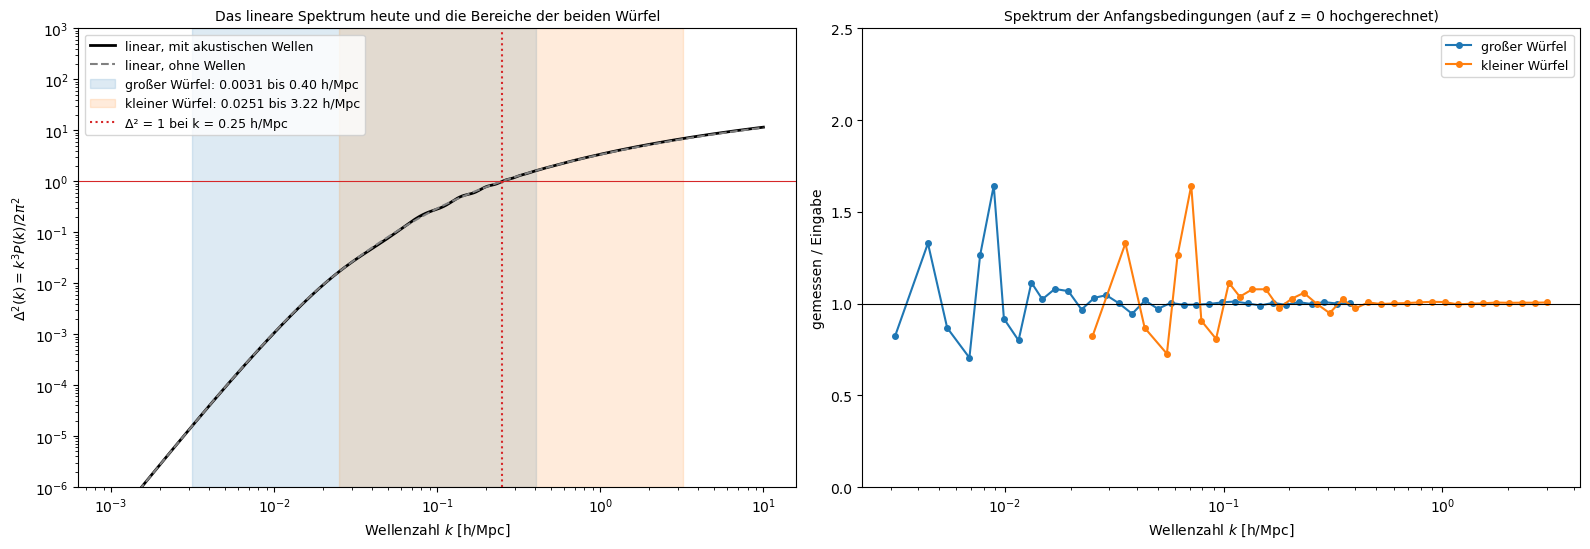

Würfel groß: Anfangsspektrum / Eingabe = 1.009 ± 0.035 (Bins mit 5 k_f < k < 0.3 k_Nyq); Zelle 7.81 Mpc/h


Würfel klein: Anfangsspektrum / Eingabe = 1.012 ± 0.035 (Bins mit 5 k_f < k < 0.3 k_Nyq); Zelle 0.98 Mpc/h
nichtlinear ab k = 0.25 h/Mpc, also auf Skalen unter 2π/k = 25 Mpc/h; σ₈ = 0.811


In [5]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
D2 = lambda k, w=True: k**3 * plin(k, w) / (2 * np.pi**2)
kk = np.geomspace(1e-3, 10, 600)
ax.loglog(kk, D2(kk), color="k", lw=2, label="linear, mit akustischen Wellen")
ax.loglog(kk, D2(kk, False), color="0.5", ls="--", label="linear, ohne Wellen")
ax.axhline(1, color="C3", lw=0.8)
for s, col, lab in [(BIG, "C0", "großer Würfel"), (SMALL, "C1", "kleiner Würfel")]:
    ax.axvspan(2 * np.pi / s["L"], np.pi * s["N"] / s["L"], color=col, alpha=0.15, label=f"{lab}: {2 * np.pi / s['L']:.4f} bis {np.pi * s['N'] / s['L']:.2f} h/Mpc")
ax.axvline(k_nl, color="C3", ls=":", label=f"Δ² = 1 bei k = {k_nl:.2f} h/Mpc")
ax.set_ylim(1e-6, 1e3)
ax.set_xlabel("Wellenzahl $k$ [h/Mpc]")
ax.set_ylabel(r"$\Delta^2(k) = k^3 P(k) / 2\pi^2$")
ax.set_title("Das lineare Spektrum heute und die Bereiche der beiden Würfel", fontsize=10)
ax.legend(fontsize=9, loc="upper left")
for s, col, lab in [(BIG, "C0", "großer Würfel"), (SMALL, "C1", "kleiner Würfel")]:
    k, p = power(s["delta_lin"], s["L"], deconv=False)
    ax2.semilogx(k, p / plin(k), "o-", color=col, ms=4, label=lab)
ax2.axhline(1, color="k", lw=0.8)
ax2.set_ylim(0, 2.5)
ax2.set_xlabel("Wellenzahl $k$ [h/Mpc]")
ax2.set_ylabel("gemessen / Eingabe")
ax2.set_title("Spektrum der Anfangsbedingungen (auf z = 0 hochgerechnet)", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

for s, lab in [(BIG, "groß"), (SMALL, "klein")]:
    k, p = power(s["delta_lin"], s["L"], deconv=False)
    m = (k > 5 * 2 * np.pi / s["L"]) & (k < 0.3 * np.pi * s["N"] / s["L"])
    print(f"Würfel {lab}: Anfangsspektrum / Eingabe = {np.mean(p[m] / plin(k[m])):.3f} ± {np.std(p[m] / plin(k[m])):.3f} "
          f"(Bins mit 5 k_f < k < 0.3 k_Nyq); Zelle {s['L'] / s['N']:.2f} Mpc/h")
print(f"nichtlinear ab k = {k_nl:.2f} h/Mpc, also auf Skalen unter 2π/k = {2 * np.pi / k_nl:.0f} Mpc/h; σ₈ = {sigma_lin(8):.3f}")

* Links $\Delta^2(k)$ des linearen Spektrums heute, mit akustischen Wellen (schwarz) und ohne (grau); die Wellen sind die kleinen Stufen zwischen 0.05 und 0.3 h/Mpc. Der große Würfel erfasst 0.0031 bis 0.40 h/Mpc, der kleine 0.025 bis 3.2 h/Mpc, zusammen drei Größenordnungen. Rechts das Spektrum der gewürfelten Anfangsfelder geteilt durch die Eingabe. Bei kleinem $k$ streut es stark, bis ±60 %, weil dort nur wenige Moden in einem Bin liegen; bei großem $k$ liegt es auf 1.
* Zwischen fünf Grundmoden und 0.3 $k_\text{Nyq}$ ist das Verhältnis 1.009 ± 0.035 (groß) und 1.012 ± 0.035 (klein). Ein Teilchen wiegt im großen Würfel 4.2·10¹³ M☉/h, so viel wie ein Galaxienhaufen, im kleinen 8.1·10¹⁰ M☉/h, etwa ein Zehntel der Milchstraße mit ihrem Halo.
* Zur Vorhersage: $\Delta^2 = 1$ bei k = 0.25 h/Mpc, also auf Skalen unter $2\pi/k$ = 25 Mpc/h (37 Mpc). $\sigma_8$ = 0.811 heißt, dass schon Kugeln von 8 Mpc/h nichtlinear sind.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-2"></a>

##### *2. Das kosmische Netz entsteht*

Wie sieht der kleine Würfel bei z = 3, z = 1 und heute aus, und wie viel des Volumens nehmen die Leeren ein? Vorher vorhersagen: Wird der Anteil des Volumens mit $\delta < -0.5$ mit der Zeit größer oder kleiner?

Der Code zeigt eine Scheibe von 20 Mpc/h Dicke durch den kleinen Würfel zu drei Zeiten, als $\log_{10}(1 + \delta)$ gemittelt über die Dicke. Er gibt aus, welcher Anteil der Zellen dichter als das Zehnfache des Mittels ist, welcher Anteil leerer als die Hälfte und wie viel Masse in diesen Zellen steckt.

**Hintergrund & Fachbegriffe:**
- **Kosmisches Netz:** Haufen an den Knoten, Filamente dazwischen, Wände und große Leeren; es entsteht, weil die Materie zuerst entlang einer Achse kollabiert (Zel'dovich-Pfannkuchen), dann entlang einer zweiten.
- **Leere:** ein Gebiet mit deutlich weniger Materie als im Mittel; die Materie strömt aus ihm heraus, deshalb werden Leeren mit der Zeit leerer und größer.

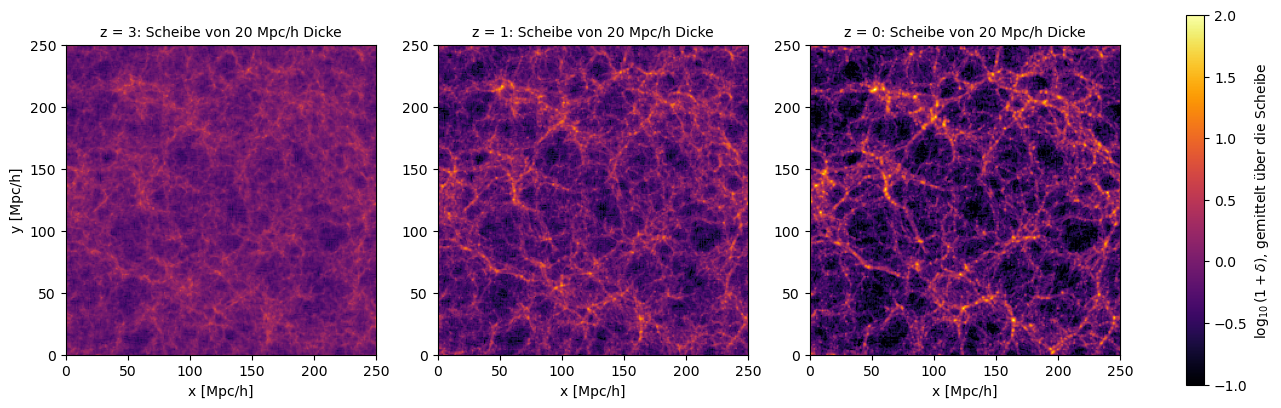

z = 3: δ > 9 in 0.17% des Volumens mit 2.5% der Masse; δ < −0.5 in 29.2% des Volumens mit 9.5% der Masse; dichteste Zelle δ = 145
z = 1: δ > 9 in 0.97% des Volumens mit 20.4% der Masse; δ < −0.5 in 54.2% des Volumens mit 11.6% der Masse; dichteste Zelle δ = 618
z = 0: δ > 9 in 1.33% des Volumens mit 39.6% der Masse; δ < −0.5 in 68.1% des Volumens mit 9.9% der Masse; dichteste Zelle δ = 1833


In [6]:
fig, axs = plt.subplots(1, 3, figsize=(17, 6))
n, L = SMALL["N"], SMALL["L"]
thick = int(20 / (L / n))
STATS2 = {}
for ax, a in zip(axs, [0.25, 0.5, 1.0]):
    d = SMALL["snaps"][a]
    img = np.log10(np.maximum(1 + d[:thick].mean(axis=0), 1e-2))
    im = ax.imshow(img.T, origin="lower", extent=[0, L, 0, L], cmap="inferno", vmin=-1, vmax=2)
    ax.set_title(f"z = {1 / a - 1:.0f}: Scheibe von {thick * L / n:.0f} Mpc/h Dicke", fontsize=10)
    ax.set_xlabel("x [Mpc/h]")
    STATS2[a] = (np.mean(d > 9), np.mean((1 + d) * (d > 9)), np.mean(d < -0.5), np.mean((1 + d) * (d < -0.5)), d.max())
axs[0].set_ylabel("y [Mpc/h]")
fig.colorbar(im, ax=axs, shrink=0.8, label=r"$\log_{10}(1 + \delta)$, gemittelt über die Scheibe")
plt.show()

for a, (v_hi, m_hi, v_lo, m_lo, dmax) in STATS2.items():
    print(f"z = {1 / a - 1:.0f}: δ > 9 in {v_hi:.2%} des Volumens mit {m_hi:.1%} der Masse; δ < −0.5 in {v_lo:.1%} des Volumens mit {m_lo:.1%} der Masse; "
          f"dichteste Zelle δ = {dmax:.0f}")

* Scheiben von 20 Mpc/h Dicke durch den kleinen Würfel bei z = 3, 1 und 0. Bei z = 3 ist das Netz schon angelegt, aber kontrastarm. Bis heute leeren sich die Gebiete dazwischen, und die Materie sammelt sich in Filamenten und an deren Knoten, wo die hellsten Punkte die Haufen sind.
* Bei z = 3 haben 29 % des Volumens $\delta < -0.5$, bei z = 1 54 %, heute 68 %; diese Leeren enthalten nur 10 % der Masse. Umgekehrt stecken heute 40 % der Masse in 1.3 % des Volumens mit $\delta > 9$. Die dichteste Zelle (1 Mpc/h groß) hat heute $\delta$ = 1833, bei z = 3 erst 145.
* Zur Vorhersage: größer, von 29 % auf 68 %. Leeren dehnen sich aus, weil ihre Materie zu den dichteren Rändern strömt.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-3"></a>

##### *3. Wächst die Simulation richtig?*

Wachsen die großen Moden genau wie in der linearen Theorie, und ab welcher Wellenzahl wird das Spektrum nichtlinear oder von der Auflösung des Gitters gebremst? Vorher vorhersagen: Liegt die nichtlineare Leistung bei k = 1 h/Mpc über oder unter der linearen?

Für jede Mode kennt der Code das Anfangsfeld. Er teilt deshalb das Spektrum am Ende durch das Spektrum desselben Anfangsfelds mal $D^2$. So fällt die Streuung der Moden heraus, und es bleibt nur der Fehler des Codes oder echtes nichtlineares Wachstum. Links steht das für den großen Würfel bei z = 0, rechts für den kleinen bei z = 3, 1 und 0, jeweils mit der Wellenzahl, bei der $\Delta^2_\text{lin} = 1$ wird. Eine graue Linie markiert ein Fünftel der Nyquist-Wellenzahl, wo die Auflösung zu bremsen beginnt (Theorie, Abschnitt 4). Im kleinen Würfel zieht der Code das **Schrotrauschen** $V/N$ ab und zeigt nur Wellenzahlen bis zur halben Nyquist-Wellenzahl.

**Hintergrund & Fachbegriffe:**
- **Nichtlineares Wachstum:** Sobald Strukturen kollabieren, wächst die Leistung auf kleinen Skalen viel schneller als linear; Haufen sind tausendfach dichter als das Mittel.
- **Auflösungsgrenze:** Das Gitter glättet die Kraft auf einigen Zellen; kleinere Haufen bleiben zu wenig dicht, und das Spektrum fällt dort zu niedrig aus.
- **Schrotrauschen:** Weil die Masse in einzelnen Teilchen steckt, hat selbst eine zufällige Verteilung ein Spektrum, $P = V/N$; es zählt dort, wo das echte Spektrum klein wird.

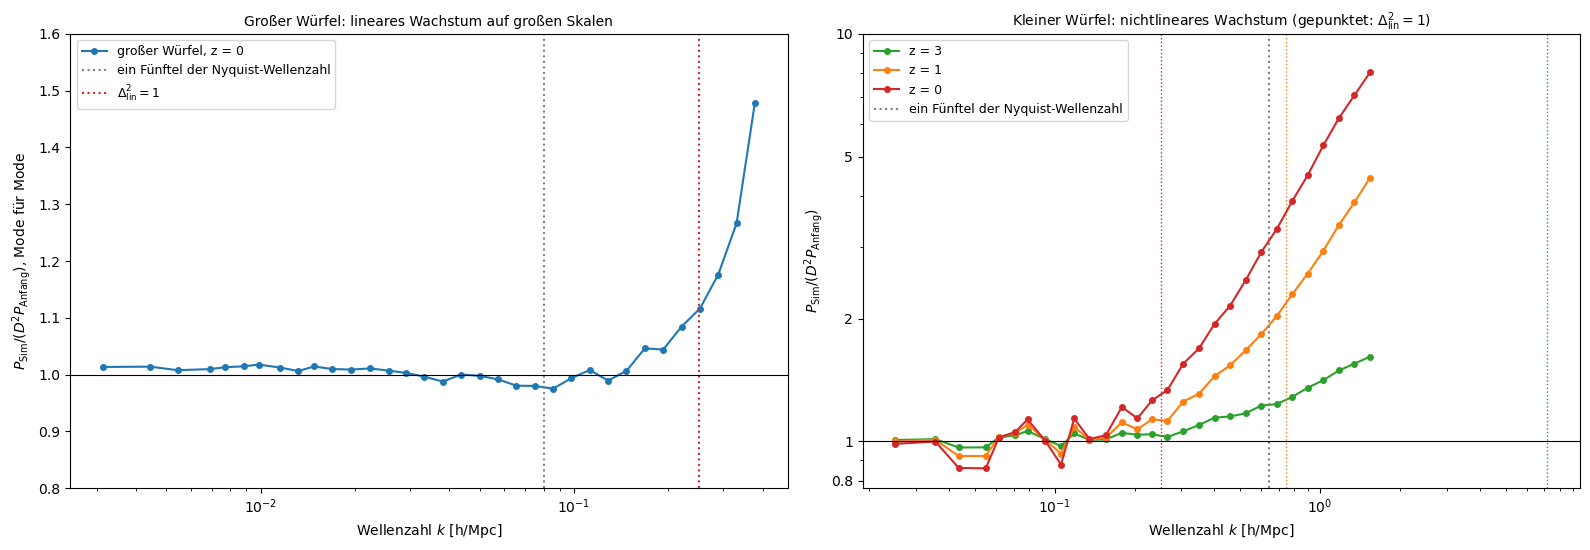

großer Würfel, k < 0.1 h/Mpc: Verhältnis 1.003 ± 0.012 (24 Bins); bei k = 0.2: 1.05
kleiner Würfel z = 3: Verhältnis bei k = 0.1: 0.99, k = 0.3: 1.05, k = 1: 1.40, k = 1.5: 1.6
kleiner Würfel z = 1: Verhältnis bei k = 0.1: 0.96, k = 0.3: 1.23, k = 1: 2.86, k = 1.5: 4.4
kleiner Würfel z = 0: Verhältnis bei k = 0.1: 0.93, k = 0.3: 1.52, k = 1: 5.15, k = 1.5: 8.0


In [7]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
k0, p0 = power(BIG["delta_lin"], BIG["L"], deconv=False)
k1, p1 = power(BIG["delta"], BIG["L"])
RATIO_BIG = p1 / p0
ax.semilogx(k1, RATIO_BIG, "o-", color="C0", ms=4, label="großer Würfel, z = 0")
ax.axvline(0.2 * np.pi * BIG["N"] / BIG["L"], color="0.5", ls=":", label="ein Fünftel der Nyquist-Wellenzahl")
ax.axvline(k_nl, color="C3", ls=":", label=r"$\Delta^2_\mathrm{lin} = 1$")
ax.axhline(1, color="k", lw=0.8)
ax.set_ylim(0.8, 1.6)
ax.set_xlabel("Wellenzahl $k$ [h/Mpc]")
ax.set_ylabel(r"$P_\mathrm{Sim} / (D^2 P_\mathrm{Anfang})$, Mode für Mode")
ax.set_title("Großer Würfel: lineares Wachstum auf großen Skalen", fontsize=10)
ax.legend(fontsize=9)
k0s, p0s = power(SMALL["delta_lin"], SMALL["L"], deconv=False)
NL = {}
for a, col in [(0.25, "C2"), (0.5, "C1"), (1.0, "C3")]:
    k, p = power(SMALL["snaps"][a], SMALL["L"])
    keep = k < 0.5 * np.pi * SMALL["N"] / SMALL["L"]                        # bis zur halben Nyquist-Wellenzahl
    NL[a] = (k[keep], (p - SMALL["L"] ** 3 / SMALL["N"] ** 3)[keep] / (p0s[keep] * growth(a) ** 2))   # ohne Schrotrauschen V/N
    k = k[keep]
    knl_a = np.exp(np.interp(0.0, np.log(KH**3 * plin(KH) * growth(a) ** 2 / (2 * np.pi**2)), LNK))
    ax2.loglog(k, NL[a][1], "o-", color=col, ms=4, label=f"z = {1 / a - 1:.0f}")
    ax2.axvline(knl_a, color=col, ls=":", lw=1)
ax2.axvline(0.2 * np.pi * SMALL["N"] / SMALL["L"], color="0.5", ls=":", label="ein Fünftel der Nyquist-Wellenzahl")
ax2.axhline(1, color="k", lw=0.8)
ax2.set_xlabel("Wellenzahl $k$ [h/Mpc]")
ax2.set_ylabel(r"$P_\mathrm{Sim} / (D^2 P_\mathrm{Anfang})$")
ax2.set_yticks([0.8, 1, 2, 5, 10])
ax2.set_yticklabels(["0.8", "1", "2", "5", "10"])
ax2.set_title(r"Kleiner Würfel: nichtlineares Wachstum (gepunktet: $\Delta^2_\mathrm{lin} = 1$)", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

m = k1 < 0.1
print(f"großer Würfel, k < 0.1 h/Mpc: Verhältnis {RATIO_BIG[m].mean():.3f} ± {RATIO_BIG[m].std():.3f} ({m.sum()} Bins); bei k = 0.2: {np.interp(0.2, k1, RATIO_BIG):.2f}")
for a, (k, r) in NL.items():
    print(f"kleiner Würfel z = {1 / a - 1:.0f}: Verhältnis bei k = 0.1: {np.interp(0.1, k, r):.2f}, k = 0.3: {np.interp(0.3, k, r):.2f}, "
          f"k = 1: {np.interp(1.0, k, r):.2f}, k = {k[-1]:.1f}: {r[-1]:.1f}")

* Links der große Würfel: das Spektrum am Ende geteilt durch das Spektrum derselben Moden am Anfang mal $D^2$. Bis k = 0.1 h/Mpc liegt es bei 1.003 ± 0.012; die großen Moden wachsen genau linear. Darüber steigt es, weil Strukturen nichtlinear werden, bei k = 0.2 um 5 %. Die Entfaltung der CIC-Glättung hält die Kraft bis über ein Fünftel der Nyquist-Wellenzahl (grau) richtig.
* Rechts der kleine Würfel. Bei z = 3 beginnt das nichtlineare Wachstum erst oberhalb von k ≈ 0.5 (bei k = 1 sind es 40 % mehr). Bei z = 1 ist es bei k = 1 das 2.9-Fache, heute das 5.2-Fache und bei k = 1.5 das 8-Fache. Je später, desto weiter wandert die Grenze der linearen Theorie zu großen Skalen (gepunktete Linien). Zwischen k = 0.05 und 0.1 streuen die Werte um 5 bis 10 %, weil es dort nur wenige Moden gibt und die nichtlineare Kopplung jede einzelne etwas verschiebt.
* Zur Vorhersage: darüber, heute um das Fünffache. Bei k = 1 liegt die Simulation schon über einem Fünftel der Nyquist-Wellenzahl (0.64 h/Mpc); vermutlich bremst das Gitter dort die kleinsten Haufen, und eine feinere Simulation fände noch mehr Leistung.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-4"></a>

##### *4. Der BAO-Peak in der Simulation*

Sieht man den Schallhorizont des frühen Universums in der Verteilung der Teilchen heute, und wo liegt der Peak? Vorher vorhersagen: Wird der Peak durch die nichtlineare Entwicklung schärfer, breiter oder verschwindet er?

Der Code rechnet die **Korrelationsfunktion** $\xi(r)$ des großen Würfels aus dem Spektrum, $\xi(\mathbf r) = \langle\delta(\mathbf x)\,\delta(\mathbf x + \mathbf r)\rangle$, gemittelt in Ringen von 4 Mpc/h. Er zeichnet $r^2\xi(r)$ neben der linearen Erwartung mit und ohne akustische Wellen. Den Peak sucht er mit einer Parabel durch die drei höchsten Punkte zwischen 80 und 120 Mpc/h.

**Hintergrund & Fachbegriffe:**
- **Korrelationsfunktion:** um wie viel wahrscheinlicher es ist, im Abstand $r$ von einem Teilchen ein weiteres zu finden, verglichen mit einer zufälligen Verteilung; die Fourier-Transformierte des Spektrums.
- **Verschmieren des Peaks:** Die Teilchen haben sich seit dem Anfang im Mittel um einige Mpc/h bewegt (der Code gibt den Wert aus); das verschmiert die scharfe Schale des Schallhorizonts.

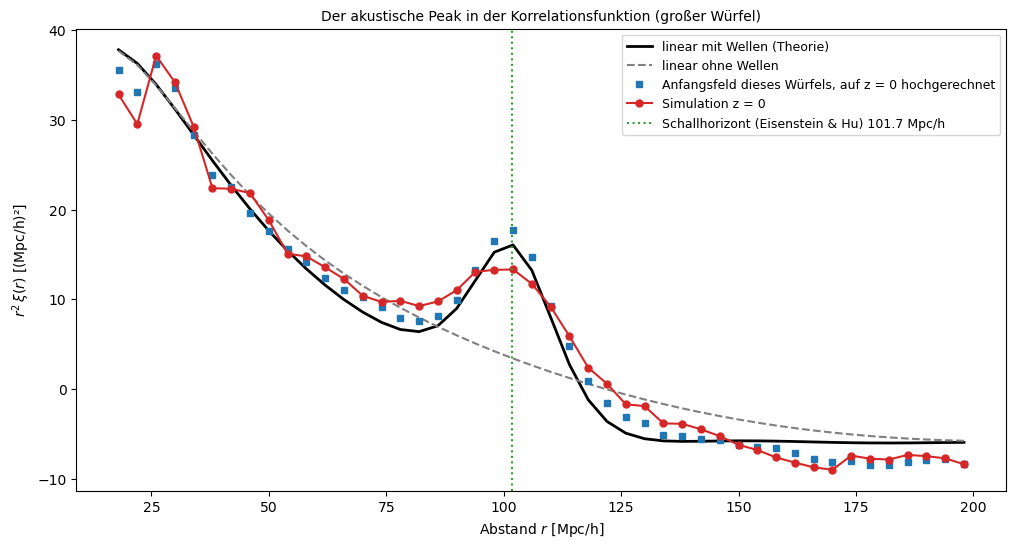

Theorie linear   : Peak bei  100.9 Mpc/h, r²ξ bei 102 Mpc/h =  16.1
Anfangsfeld      : Peak bei  101.1 Mpc/h, r²ξ bei 102 Mpc/h =  17.7
Simulation z = 0 : Peak bei  100.1 Mpc/h, r²ξ bei 102 Mpc/h =  13.3
mittlere Verschiebung der Teilchen seit dem Anfang (linear, 3D): 10.1 Mpc/h


In [8]:
n, L = BIG["N"], BIG["L"]
U, RG = offsets(n, L)
bins = np.arange(16.0, 204.0, 4.0)
rc = 0.5 * (bins[1:] + bins[:-1])
ib = np.digitize(RG.ravel(), bins)
cnt = np.bincount(ib, minlength=len(bins) + 1)[1:-1]
XI = {}
for lab, d, w in [("Simulation z = 0", BIG["delta"], cic_window(n)), ("Anfangsfeld (linear)", BIG["delta_lin"], 1.0)]:
    xi = ifft(np.abs(fft(d) / w) ** 2, n) / n**3
    XI[lab] = np.bincount(ib, xi.ravel(), len(bins) + 1)[1:-1] / cnt
xi_th = {w: np.array([np.trapz(KH**3 * plin(KH, w) * np.exp(-(KH / 1.0) ** 2) * np.sinc(KH * r / np.pi) / (2 * np.pi**2), LNK) for r in rc])
         for w in (True, False)}


def bao_peak(xi):
    m = (rc > 80) & (rc < 120)
    y = (rc**2 * xi)[m]
    j = np.clip(np.argmax(y), 1, m.sum() - 2)
    c = np.polyfit(rc[m][j - 1:j + 2], y[j - 1:j + 2], 2)
    return -c[1] / (2 * c[0])


fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(rc, rc**2 * xi_th[True], color="k", lw=2, label="linear mit Wellen (Theorie)")
ax.plot(rc, rc**2 * xi_th[False], color="0.5", ls="--", label="linear ohne Wellen")
ax.plot(rc, rc**2 * XI["Anfangsfeld (linear)"], "s", color="C0", ms=4, label="Anfangsfeld dieses Würfels, auf z = 0 hochgerechnet")
ax.plot(rc, rc**2 * XI["Simulation z = 0"], "o-", color="C3", ms=5, label="Simulation z = 0")
ax.axvline(S_EH * PLANCK["h"], color="C2", ls=":", label=f"Schallhorizont (Eisenstein & Hu) {S_EH * PLANCK['h']:.1f} Mpc/h")
ax.set_xlabel("Abstand $r$ [Mpc/h]")
ax.set_ylabel(r"$r^2\,\xi(r)$ [(Mpc/h)²]")
ax.set_title("Der akustische Peak in der Korrelationsfunktion (großer Würfel)", fontsize=10)
ax.legend(fontsize=9)
plt.show()

for lab, xi in [("Theorie linear", xi_th[True]), ("Anfangsfeld", XI["Anfangsfeld (linear)"]), ("Simulation z = 0", XI["Simulation z = 0"])]:
    i100 = np.argmin(abs(rc - 102))
    print(f"{lab:17s}: Peak bei {bao_peak(xi):6.1f} Mpc/h, r²ξ bei 102 Mpc/h = {rc[i100]**2 * xi[i100]:5.1f}")
print(f"mittlere Verschiebung der Teilchen seit dem Anfang (linear, 3D): {np.sqrt(np.trapz(KH * plin(KH) / (2 * np.pi**2), LNK)):.1f} Mpc/h")

* $r^2\xi(r)$ des großen Würfels heute (rot), des Anfangsfelds auf heute hochgerechnet (blau) und der linearen Theorie mit (schwarz) und ohne Wellen (grau). Der Peak bei 100 Mpc/h ist in der Theorie, im Anfangsfeld und in der Simulation heute da; ohne Wellen fehlt er. Das Anfangsfeld folgt der Theorie bis auf die Streuung dieses einen Würfels.
* Die Parabel gibt den Peak bei 100.9 (Theorie), 101.1 (Anfangsfeld) und 100.1 Mpc/h (Simulation heute). Seine Höhe bei 102 Mpc/h sinkt von 17.7 auf 13.3, und er wird breiter, denn die Teilchen sind seit dem Anfang im Mittel um 10 Mpc/h gewandert. Die Lage verschiebt sich um 1 Mpc/h (1 %), etwa so viel, wie sich bei Ringen von 4 Mpc/h ablesen lässt.
* Zur Vorhersage: breiter und niedriger, aber er bleibt. Deshalb taugt er als Lineal (cosmology_bao); DESI macht die Verschmierung vor der Messung teilweise rückgängig (Rekonstruktion).

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-5"></a>

##### *5. Wie stark schwankt die Dichte in Kugeln?*

Wie groß ist die Streuung $\sigma(R)$ des Dichtekontrasts in Kugeln von 3 bis 300 Mpc/h, und bis zu welchem Radius stimmt die lineare Theorie? Vorher vorhersagen: Ist das gemessene $\sigma_8$ größer oder kleiner als die 0.811 der linearen Theorie?

Der Code mittelt die Dichte in Kugeln um jeden Gitterpunkt (Theorie, Abschnitt 5): im kleinen Würfel für $R$ = 3 bis 40 Mpc/h, im großen für 30 bis 250 Mpc/h. Dasselbe macht er mit dem linearen Anfangsfeld desselben Würfels. Daneben steht $\sigma(R)$ aus dem Integral über das lineare Spektrum. Das Verhältnis Simulation / Anfangsfeld zeigt die nichtlineare Verstärkung ohne die Streuung der Moden.

**Hintergrund & Fachbegriffe:**
- **$\sigma_8$:** die Streuung der Dichte in Kugeln von 8 Mpc/h Radius, linear auf heute hochgerechnet; die übliche Angabe für die Amplitude der Schwankungen.
- **Glättung durch das Gitter:** CIC verteilt jedes Teilchen über eine Zelle; für Kugeln mit wenigen Zellen Radius ist die gemessene Streuung deshalb etwas zu klein. Der Code beginnt bei drei Zellen.

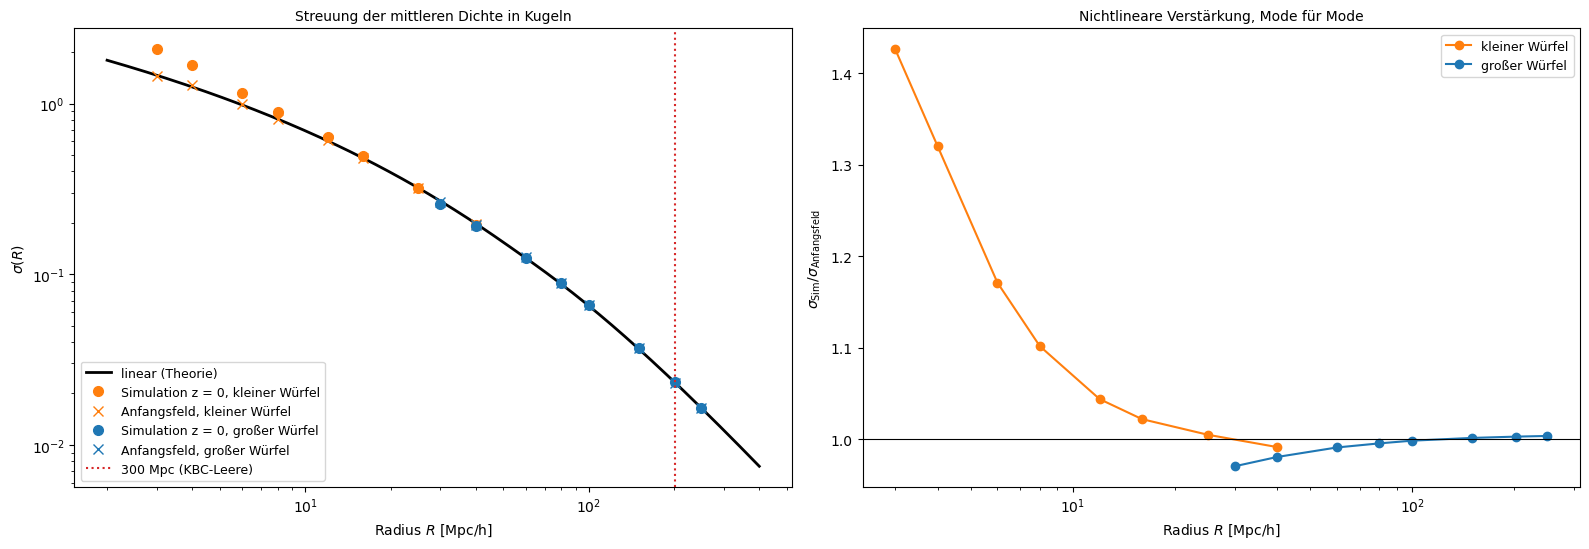

L =    250, R =     3 Mpc/h: σ Simulation 2.0819, Anfangsfeld 1.4596, Theorie 1.4629; Verhältnis 1.426
L =    250, R =     4 Mpc/h: σ Simulation 1.6900, Anfangsfeld 1.2801, Theorie 1.2498; Verhältnis 1.320
L =    250, R =     6 Mpc/h: σ Simulation 1.1575, Anfangsfeld 0.9884, Theorie 0.9802; Verhältnis 1.171
L =    250, R =     8 Mpc/h: σ Simulation 0.8963, Anfangsfeld 0.8136, Theorie 0.8110; Verhältnis 1.102
L =    250, R =    12 Mpc/h: σ Simulation 0.6339, Anfangsfeld 0.6074, Theorie 0.6039; Verhältnis 1.044
L =    250, R =    16 Mpc/h: σ Simulation 0.4922, Anfangsfeld 0.4818, Theorie 0.4792; Verhältnis 1.022
L =    250, R =    25 Mpc/h: σ Simulation 0.3208, Anfangsfeld 0.3193, Theorie 0.3209; Verhältnis 1.005
L =    250, R =    40 Mpc/h: σ Simulation 0.1939, Anfangsfeld 0.1956, Theorie 0.1979; Verhältnis 0.991
L =   2000, R =    30 Mpc/h: σ Simulation 0.2562, Anfangsfeld 0.2640, Theorie 0.2681; Verhältnis 0.970
L =   2000, R =    40 Mpc/h: σ Simulation 0.1909, Anfangsfeld 0.1947, The

In [9]:
R_SMALL = np.array([3, 4, 6, 8, 12, 16, 25, 40])
R_BIG = np.array([30, 40, 60, 80, 100, 150, R_KBC, 250])
SIG = {}
for s, Rs in [(SMALL, R_SMALL), (BIG, R_BIG)]:
    for R in Rs:
        SIG[(s["L"], float(R))] = (in_spheres(s["delta"], s["L"], R).std(), in_spheres(s["delta_lin"], s["L"], R).std())
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
rr = np.geomspace(2, 400, 200)
ax.loglog(rr, [sigma_lin(r) for r in rr], color="k", lw=2, label="linear (Theorie)")
for s, Rs, col, lab in [(SMALL, R_SMALL, "C1", "kleiner Würfel"), (BIG, R_BIG, "C0", "großer Würfel")]:
    ax.loglog(Rs, [SIG[(s["L"], float(R))][0] for R in Rs], "o", color=col, ms=7, label=f"Simulation z = 0, {lab}")
    ax.loglog(Rs, [SIG[(s["L"], float(R))][1] for R in Rs], "x", color=col, ms=7, label=f"Anfangsfeld, {lab}")
    ax2.semilogx(Rs, [SIG[(s["L"], float(R))][0] / SIG[(s["L"], float(R))][1] for R in Rs], "o-", color=col, ms=6, label=lab)
ax.axvline(R_KBC, color="C3", ls=":", label="300 Mpc (KBC-Leere)")
ax.set_xlabel("Radius $R$ [Mpc/h]")
ax.set_ylabel(r"$\sigma(R)$")
ax.set_title("Streuung der mittleren Dichte in Kugeln", fontsize=10)
ax.legend(fontsize=9)
ax2.axhline(1, color="k", lw=0.8)
ax2.set_xlabel("Radius $R$ [Mpc/h]")
ax2.set_ylabel(r"$\sigma_\mathrm{Sim} / \sigma_\mathrm{Anfangsfeld}$")
ax2.set_title("Nichtlineare Verstärkung, Mode für Mode", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

for (L, R), (sn, sl) in SIG.items():
    print(f"L = {L:6.0f}, R = {R:5.0f} Mpc/h: σ Simulation {sn:.4f}, Anfangsfeld {sl:.4f}, Theorie {sigma_lin(R):.4f}; Verhältnis {sn / sl:.3f}")

* Links $\sigma(R)$: Punkte für die Simulation heute, Kreuze für dasselbe Anfangsfeld, die Linie für die lineare Theorie. Ab etwa 20 Mpc/h liegen alle drei aufeinander, darunter liegt die Simulation darüber. Rechts das Verhältnis Simulation / Anfangsfeld.
* $\sigma_8$ aus der Simulation ist 0.896, 10 % über dem linearen Wert (Anfangsfeld 0.814). Bei 3 Mpc/h sind es 43 % mehr, bei 25 Mpc/h nur noch 0.5 %. Bei 300 Mpc (202 Mpc/h) ist $\sigma$ = 0.0232, linear 0.0231. Im großen Würfel liegt $\sigma$ bei 30 Mpc/h 3 % unter dem Anfangsfeld; die Kugel hat dort knapp vier Zellen Radius, und Gitter und CIC glätten.
* Zur Vorhersage: größer. Die nichtlineare Entwicklung erhöht die Streuung auf kleinen Skalen, weil Haufen dichter werden, als die lineare Theorie erlaubt.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-6"></a>

##### *6. Die Verteilung der Dichte in Kugeln*

Wie sieht die Verteilung von $\delta_R$ aus, gaußisch oder schief, und wie leer kann eine Kugel werden? Vorher vorhersagen: Liegt bei R = 8 Mpc/h der häufigste Wert über oder unter null?

Der Code zeichnet Histogramme von $\delta_R$ über alle Gitterpunkte für $R$ = 8 und 25 Mpc/h (kleiner Würfel) und 100 und 202 Mpc/h (großer Würfel). Dazu kommen eine Gaußkurve mit derselben Streuung und eine Lognormalverteilung von $1 + \delta$ mit Mittel 1 und derselben Streuung. Ausgegeben werden Schiefe, Median, häufigster Wert und kleinster Wert.

**Hintergrund & Fachbegriffe:**
- **Lognormal:** $\ln(1 + \delta)$ ist gaußisch; die Verteilung ist dann nach unten durch −1 begrenzt und hat einen langen Ausläufer zu hohen Dichten.
- **Median unter null:** Bei schiefer Verteilung mit Mittel null liegen mehr als die Hälfte aller Kugeln unter dem Mittel; das Universum besteht dem Volumen nach überwiegend aus Unterdichten.

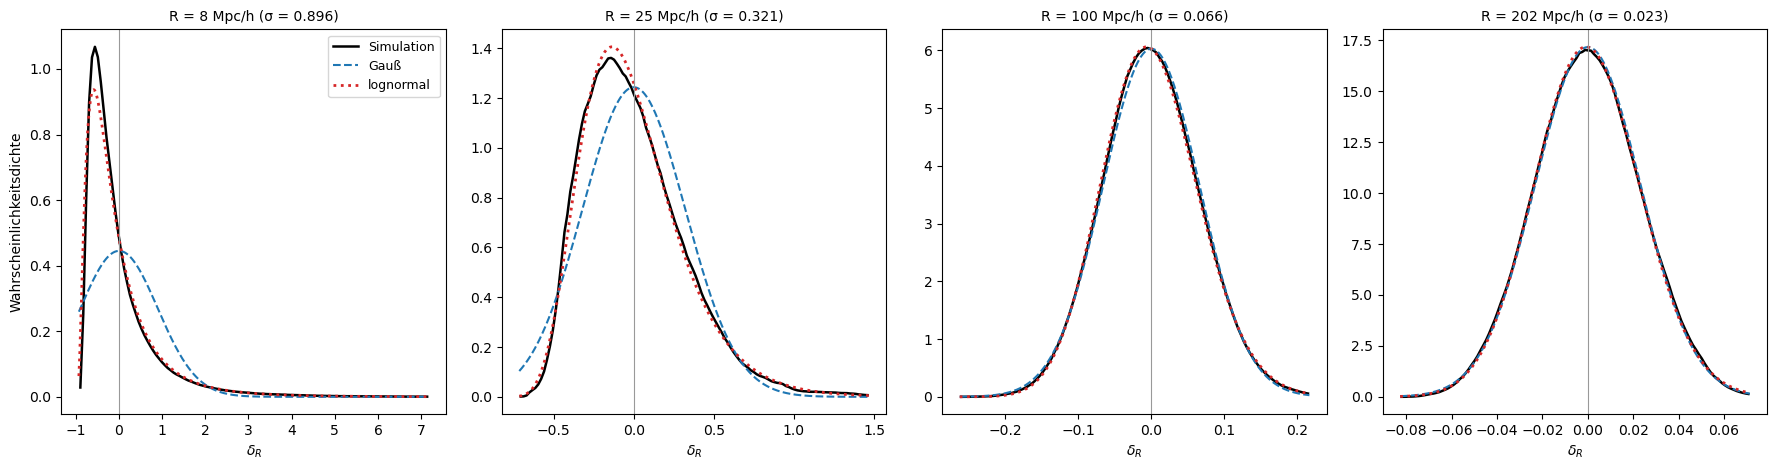

R =     8 Mpc/h: σ = 0.896, Schiefe +3.52, Median -0.267, häufigster Wert -0.559, kleinster Wert -0.931 (-1.0σ)
R =    25 Mpc/h: σ = 0.321, Schiefe +0.96, Median -0.047, häufigster Wert -0.142, kleinster Wert -0.715 (-2.2σ)
R =   100 Mpc/h: σ = 0.066, Schiefe +0.13, Median -0.001, häufigster Wert -0.005, kleinster Wert -0.263 (-4.0σ)
R =   202 Mpc/h: σ = 0.023, Schiefe +0.05, Median -0.000, häufigster Wert -0.001, kleinster Wert -0.083 (-3.6σ)


In [10]:
CASES6 = [(SMALL, 8.0), (SMALL, 25.0), (BIG, 100.0), (BIG, R_KBC)]
fig, axs = plt.subplots(1, 4, figsize=(18, 4.8))
PDF = {}
for ax, (s, R) in zip(axs, CASES6):
    d = in_spheres(s["delta"], s["L"], R).ravel()
    sg = d.std()
    lo, hi = max(-1, d.min()), np.percentile(d, 99.9)
    h, e = np.histogram(d, bins=120, range=(lo, hi), density=True)
    c = 0.5 * (e[1:] + e[:-1])
    s2 = np.log(1 + sg**2)
    x = np.linspace(lo, hi, 400)
    ax.plot(c, h, color="k", lw=1.8, label="Simulation")
    ax.plot(x, stats.norm.pdf(x, 0, sg), color="C0", ls="--", label="Gauß")
    ax.plot(x, stats.lognorm.pdf(1 + x, np.sqrt(s2), scale=np.exp(-s2 / 2)), color="C3", ls=":", lw=2, label="lognormal")
    ax.axvline(0, color="0.6", lw=0.8)
    ax.set_title(f"R = {R:.0f} Mpc/h (σ = {sg:.3f})", fontsize=10)
    ax.set_xlabel(r"$\delta_R$")
    PDF[R] = (sg, stats.skew(d), np.median(d), c[np.argmax(h)], d.min())
axs[0].set_ylabel("Wahrscheinlichkeitsdichte")
axs[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

for R, (sg, sk, med, mode, mn) in PDF.items():
    print(f"R = {R:5.0f} Mpc/h: σ = {sg:.3f}, Schiefe {sk:+.2f}, Median {med:+.3f}, häufigster Wert {mode:+.3f}, kleinster Wert {mn:+.3f} ({mn / sg:.1f}σ)")

* Histogramme von $\delta_R$ mit Gaußkurve (blau gestrichelt) und Lognormalverteilung (rot gepunktet). Bei 8 Mpc/h ist die Verteilung stark schief (Schiefe +3.5), mit einer Spitze bei −0.56 und einem langen Ausläufer bis $\delta$ = 7. Die Lognormalverteilung trifft die Form gut, die Gaußkurve nicht. Bei 25 Mpc/h ist sie noch deutlich schief (+0.96), bei 100 und 202 Mpc/h fast gaußisch (+0.13 und +0.05).
* Median und häufigster Wert liegen bei kleinen Kugeln unter null: bei 8 Mpc/h −0.27 und −0.56, bei 25 Mpc/h −0.05 und −0.14. Die leersten Kugeln haben −0.93 (8 Mpc/h), −0.72 (25 Mpc/h), −0.26 (100 Mpc/h) und −0.083 (202 Mpc/h).
* Zur Vorhersage: darunter, bei −0.56. Die meisten Kugeln von 8 Mpc/h liegen in Leeren; das Mittel null halten die wenigen sehr dichten Kugeln um Haufen.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-7"></a>

##### *7. Wie selten ist die KBC-Leere?*

Wie leer wird die leerste Kugel von 300 Mpc Radius im großen Würfel, und wie oft käme eine mit $\delta = -0.46$ im ganzen beobachtbaren Universum vor? Vorher vorhersagen: Wie viele Standardabweichungen liegt $\delta = -0.46$ unter dem Mittel, wenn $\sigma$ bei 300 Mpc etwa 0.023 ist?

Links steht die Verteilung von $\delta_R/\sigma$ für $R$ = 202 Mpc/h über alle Gitterpunkte des großen Würfels, mit der Gaußkurve. Rechts steht die Wahrscheinlichkeit, $\nu$ Standardabweichungen oder mehr unter dem Mittel zu liegen: aus der Simulation, soweit sie reicht, und aus der Gaußkurve darüber hinaus (Theorie, Abschnitt 7). Markiert sind die KBC-Leere ohne und mit ihrem Messfehler von 0.06 und die Schwelle, ab der ein Ereignis im ganzen beobachtbaren Universum nicht einmal mehr einmal vorkäme.

**Hintergrund & Fachbegriffe:**
- **Unabhängige Kugeln:** Die Kugeln um benachbarte Gitterpunkte überlappen fast ganz; unabhängig sind nur etwa so viele, wie Kugelvolumen in den Würfel passen.
- **Extrapolation:** Die Simulation kann nur Wahrscheinlichkeiten bis etwa 1/(Zahl unabhängiger Kugeln) direkt messen; darunter trägt man die Form der Verteilung weiter. Bei 300 Mpc ist sie fast gaußisch (Schritt 6), mit leicht positiver Schiefe. Der Ausläufer zu negativen Werten ist dann eher dünner als bei Gauß.

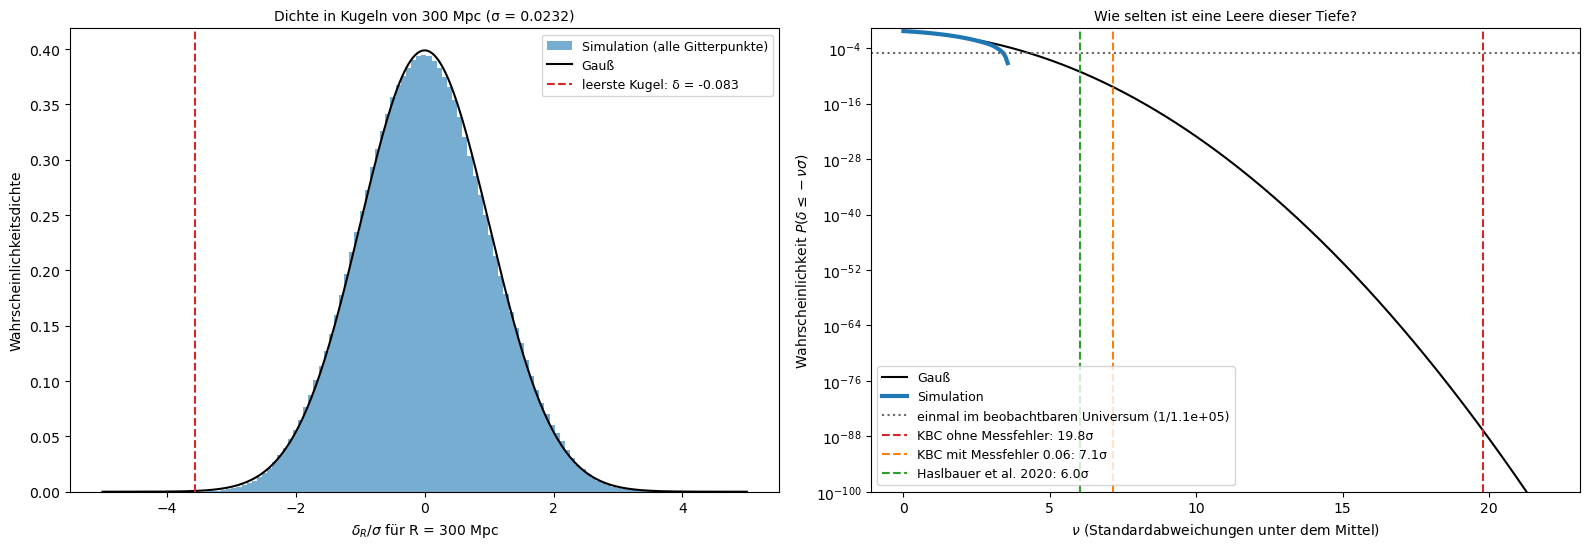

σ(300 Mpc) = 0.0232 (linear 0.0231); Schiefe +0.053; leerste Kugel δ = -0.0827 = -3.56σ; unabhängige Kugeln im Würfel ≈ 231, im beobachtbaren Universum ≈ 1.06e+05
KBC ohne Messfehler: 19.8σ, p = 1.6e-87, erwartete Zahl im beobachtbaren Universum 1.7e-82
KBC mit Messfehler: 7.1σ, p = 4.4e-13, erwartete Zahl im beobachtbaren Universum 4.6e-08
nötige Tiefe für p = 1/1e+05: δ = -0.099


In [11]:
D202 = in_spheres(BIG["delta"], BIG["L"], R_KBC).ravel()
SIG202 = D202.std()
N_BOX = BIG["L"] ** 3 / (4 / 3 * np.pi * R_KBC**3)
N_UNIVERSE = (R_HORIZON / KBC["R"]) ** 3
NU_KBC = abs(KBC["delta"]) / SIG202
NU_KBC_ERR = abs(KBC["delta"]) / np.hypot(SIG202, KBC["err"])
p_sf = lambda nu: np.exp(stats.norm.logsf(nu))
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
ax.hist(D202 / SIG202, bins=100, density=True, color="C0", alpha=0.6, label="Simulation (alle Gitterpunkte)")
x = np.linspace(-5, 5, 300)
ax.plot(x, stats.norm.pdf(x), color="k", lw=1.5, label="Gauß")
ax.axvline(D202.min() / SIG202, color="C3", ls="--", label=f"leerste Kugel: δ = {D202.min():.3f}")
ax.set_xlabel(r"$\delta_R / \sigma$ für R = 300 Mpc")
ax.set_ylabel("Wahrscheinlichkeitsdichte")
ax.set_title(f"Dichte in Kugeln von 300 Mpc (σ = {SIG202:.4f})", fontsize=10)
ax.legend(fontsize=9)
nu = np.linspace(0, 22, 500)
ax2.semilogy(nu, p_sf(nu), color="k", lw=1.5, label="Gauß")
nus = np.linspace(0, abs(D202.min()) / SIG202, 60)
ax2.semilogy(nus, [np.mean(D202 <= -v * SIG202) for v in nus], color="C0", lw=3, label="Simulation")
ax2.axhline(1 / N_UNIVERSE, color="0.4", ls=":", label=f"einmal im beobachtbaren Universum (1/{N_UNIVERSE:.1e})")
for v, col, lab in [(NU_KBC, "C3", "KBC ohne Messfehler"), (NU_KBC_ERR, "C1", "KBC mit Messfehler 0.06"), (HASLBAUER_SIGMA, "C2", "Haslbauer et al. 2020")]:
    ax2.axvline(v, color=col, ls="--", label=f"{lab}: {v:.1f}σ")
ax2.set_ylim(1e-100, 2)
ax2.set_xlabel(r"$\nu$ (Standardabweichungen unter dem Mittel)")
ax2.set_ylabel(r"Wahrscheinlichkeit $P(\delta \leq -\nu\sigma)$")
ax2.set_title("Wie selten ist eine Leere dieser Tiefe?", fontsize=10)
ax2.legend(fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()

print(f"σ(300 Mpc) = {SIG202:.4f} (linear {sigma_lin(R_KBC):.4f}); Schiefe {stats.skew(D202):+.3f}; leerste Kugel δ = {D202.min():+.4f} = {D202.min() / SIG202:.2f}σ; "
      f"unabhängige Kugeln im Würfel ≈ {N_BOX:.0f}, im beobachtbaren Universum ≈ {N_UNIVERSE:.2e}")
for lab, v in [("KBC ohne Messfehler", NU_KBC), ("KBC mit Messfehler", NU_KBC_ERR)]:
    print(f"{lab}: {v:.1f}σ, p = {p_sf(v):.1e}, erwartete Zahl im beobachtbaren Universum {N_UNIVERSE * p_sf(v):.1e}")
print(f"nötige Tiefe für p = 1/{N_UNIVERSE:.0e}: δ = {-stats.norm.isf(1 / N_UNIVERSE) * SIG202:.3f}")

* Links die Verteilung von $\delta_R/\sigma$ für 300 Mpc über alle Gitterpunkte des großen Würfels; sie liegt genau auf der Gaußkurve. Die leerste Kugel hat $\delta$ = −0.083 = −3.6σ. Bei etwa 230 unabhängigen und vielen teilweise überlappenden Kugeln ist das kein besonderer Ausreißer. Rechts die Wahrscheinlichkeit $P(\delta \le -\nu\sigma)$: Die Simulation (blau) folgt der Gaußkurve, soweit sie reicht.
* $\delta$ = −0.46 liegt 19.8σ unter dem Mittel, mit $p$ = 2·10⁻⁸⁷. Mit dem Messfehler von 0.06 bleiben 7.1σ und $p$ = 4·10⁻¹³. Im beobachtbaren Universum gibt es etwa 10⁵ Kugeln dieser Größe; erwartet würden also selbst mit Messfehler nur 5·10⁻⁸ solche Leeren. Die tiefste Leere von 300 Mpc, die man im ganzen beobachtbaren Universum einmal erwarten kann, hat $\delta$ = −0.10.
* Zur Vorhersage: 0.46 / 0.023 = 20σ. Erst der Messfehler macht daraus 7σ.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-8"></a>

##### *8. Wo Leeren dieser Tiefe häufig sind*

Bis zu welchem Radius sind Kugeln mit $\delta \le -0.46$ häufig, und wie ändert sich das, wenn der Beobachter wie wir in einer Galaxie sitzt? Vorher vorhersagen: Ist eine Leere um einen Beobachter in Materie wahrscheinlicher oder unwahrscheinlicher als um einen zufälligen Punkt?

Der Code zählt für Radien von 3 bis 100 Mpc/h, welcher Anteil der Kugeln $\delta_R \le -0.46$ hat. Einmal stehen die Kugeln um zufällige Punkte (alle Gitterpunkte), einmal um 200 000 zufällig gewählte Teilchen. Die Teilchen stehen für Beobachter, die wie wir in Materie sitzen. Für kleine Radien nimmt er den kleinen Würfel, für große den großen. Ausgegeben wird der Radius, bei dem der Anteil auf 1 % fällt, und der Median von $\delta_R$ für beide Arten von Beobachtern.

**Hintergrund & Fachbegriffe:**
- **Volumen- und Massengewicht:** Ein zufälliger Punkt liegt meist in einer Leere, denn Leeren füllen den größten Teil des Volumens. Ein zufälliges Teilchen liegt meist in einer dichten Struktur, denn dort ist die meiste Masse.
- **Lokale Leere:** Die Milchstraße liegt am Rand der Lokalen Leere (Tully & Fisher 1987), einer fast leeren Region von einigen zehn Mpc; Leeren dieser Größe sind gewöhnlich.

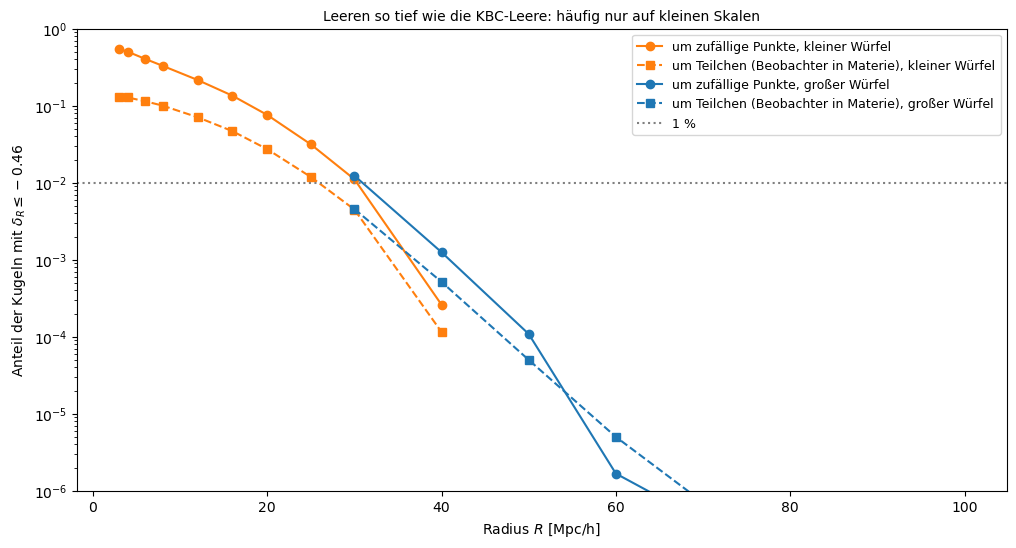

zufällige Punkte      : Anteil 1 % bei R = 30 Mpc/h (45 Mpc); R = 8: 32.96%, R = 16: 13.50%, R = 25: 3.15%, R = 40: 0.13%, R = 60: 0.00%
Beobachter in Materie : Anteil 1 % bei R = 26 Mpc/h (38 Mpc); R = 8: 10.03%, R = 16: 4.68%, R = 25: 1.19%, R = 40: 0.05%, R = 60: 0.00%
R = 8 Mpc/h: Median δ_R um zufällige Punkte -0.267, um Teilchen +0.469
R = 25 Mpc/h: Median δ_R um zufällige Punkte -0.047, um Teilchen +0.099
R = 60 Mpc/h: Median δ_R um zufällige Punkte -0.006, um Teilchen +0.016


In [12]:
rng = np.random.default_rng(8)
FRAC = {}
for s, Rs in [(SMALL, [3, 4, 6, 8, 12, 16, 20, 25, 30, 40]), (BIG, [30, 40, 50, 60, 80, 100])]:
    cells = np.floor(s["pos"][rng.choice(len(s["pos"]), 200_000, replace=False)]).astype(int) % s["N"]
    for R in Rs:
        d = in_spheres(s["delta"], s["L"], R)
        do = d[cells[:, 0], cells[:, 1], cells[:, 2]]
        FRAC[(s["L"], R)] = (np.mean(d <= KBC["delta"]), np.mean(do <= KBC["delta"]), np.median(d), np.median(do))
fig, ax = plt.subplots(figsize=(12, 6))
for L_, col, lab in [(SMALL["L"], "C1", "kleiner Würfel"), (BIG["L"], "C0", "großer Würfel")]:
    Rs = [R for (L2, R) in FRAC if L2 == L_]
    ax.semilogy(Rs, [max(FRAC[(L_, R)][0], 1e-7) for R in Rs], "o-", color=col, label=f"um zufällige Punkte, {lab}")
    ax.semilogy(Rs, [max(FRAC[(L_, R)][1], 1e-7) for R in Rs], "s--", color=col, label=f"um Teilchen (Beobachter in Materie), {lab}")
ax.axhline(0.01, color="0.5", ls=":", label="1 %")
ax.set_ylim(1e-6, 1)
ax.set_xlabel("Radius $R$ [Mpc/h]")
ax.set_ylabel(r"Anteil der Kugeln mit $\delta_R \leq -0.46$")
ax.set_title("Leeren so tief wie die KBC-Leere: häufig nur auf kleinen Skalen", fontsize=10)
ax.legend(fontsize=9)
plt.show()

for j, lab in [(0, "zufällige Punkte"), (1, "Beobachter in Materie")]:
    pts = sorted((R, v[j]) for (L_, R), v in FRAC.items() if (L_ == SMALL["L"] and R <= 30) or (L_ == BIG["L"] and R > 30))
    R1 = np.exp(np.interp(np.log(0.01), np.log([max(p, 1e-9) for _, p in pts])[::-1], np.log([R for R, _ in pts])[::-1]))
    print(f"{lab:22s}: Anteil 1 % bei R = {R1:.0f} Mpc/h ({R1 / PLANCK['h']:.0f} Mpc); " +
          ", ".join(f"R = {R}: {p:.2%}" for R, p in pts if R in (8, 16, 25, 40, 60)))
for (L_, R), (fr, fo, mr, mo) in FRAC.items():
    if R in (8, 25) and L_ == SMALL["L"] or R == 60:
        print(f"R = {R} Mpc/h: Median δ_R um zufällige Punkte {mr:+.3f}, um Teilchen {mo:+.3f}")

* Der Anteil der Kugeln mit $\delta_R \le -0.46$ über $R$, um zufällige Punkte (Kreise) und um Teilchen (Quadrate), aus beiden Würfeln. Er fällt steil: 33 % bei 8 Mpc/h, 3 % bei 25, 0.13 % bei 40 und 0.01 % bei 50 Mpc/h. Bei 80 und 100 Mpc/h gibt es keine einzige solche Kugel. Bei 30 Mpc/h stimmen beide Würfel überein (1.2 %); bei 40 Mpc/h hat der kleine Würfel zu wenige unabhängige Kugeln, um so seltene Werte zu zählen.
* 1 % wird um zufällige Punkte bei R = 30 Mpc/h (45 Mpc) erreicht, um Beobachter in Materie schon bei 26 Mpc/h (38 Mpc). Um Teilchen ist der Median von $\delta_R$ positiv (+0.47 bei 8 Mpc/h, +0.10 bei 25, +0.016 bei 60), um zufällige Punkte negativ (−0.27, −0.05, −0.006).
* Zur Vorhersage: unwahrscheinlicher, bei 8 Mpc/h etwa um den Faktor 3 (10 % statt 33 %). Wer in einer Galaxie sitzt, sitzt meist in einer Überdichte. Leeren dieser Tiefe gibt es also, aber nur bis etwa 40 Mpc Radius, nicht bis 300 Mpc.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-9"></a>

##### *9. Die lokale Hubble-Konstante*

Wie stark streut die Hubble-Konstante, die ein Beobachter aus seiner Umgebung bis zum Radius $R$ misst, und wie hängt sie mit der Dichte um ihn zusammen? Vorher vorhersagen: Wie viele Standardabweichungen wären die +8 %, die eine KBC-Leere verlangt, bei R = 300 Mpc?

Der Code legt die Geschwindigkeiten der Teilchen im großen Würfel als Impulsdichte auf das Gitter. Für jeden Gitterpunkt als Beobachter rechnet er die beste Gerade $\delta H/H_0 = \sum v_r r / (H_0\sum r^2)$ über die Materie in der Schale von 10 Mpc/h bis $R$ (Theorie, Abschnitt 6). Die Summen sind Faltungen und gehen mit der FFT für alle Beobachter zugleich. Zum Vergleich macht er dasselbe mit dem linearen Geschwindigkeitsfeld $f\,\boldsymbol\psi$ des Anfangsfelds. Links steht die Streuung über $R$, rechts für $R$ = 300 Mpc $\delta H/H_0$ gegen die mittlere Dichte in der Kugel, mit der linearen Erwartung $-f\delta/3$ und der KBC-Leere.

**Hintergrund & Fachbegriffe:**
- **Impulsdichte:** Summe von Masse mal Geschwindigkeit pro Zelle; geteilt durch die Dichte ist sie die mittlere Geschwindigkeit der Materie dort.
- **Faltung:** $\sum_\mathbf{x} M(\mathbf x)\,K(\mathbf x - \mathbf x_0)$ für alle $\mathbf x_0$ zugleich ist ein Produkt im Fourier-Raum.

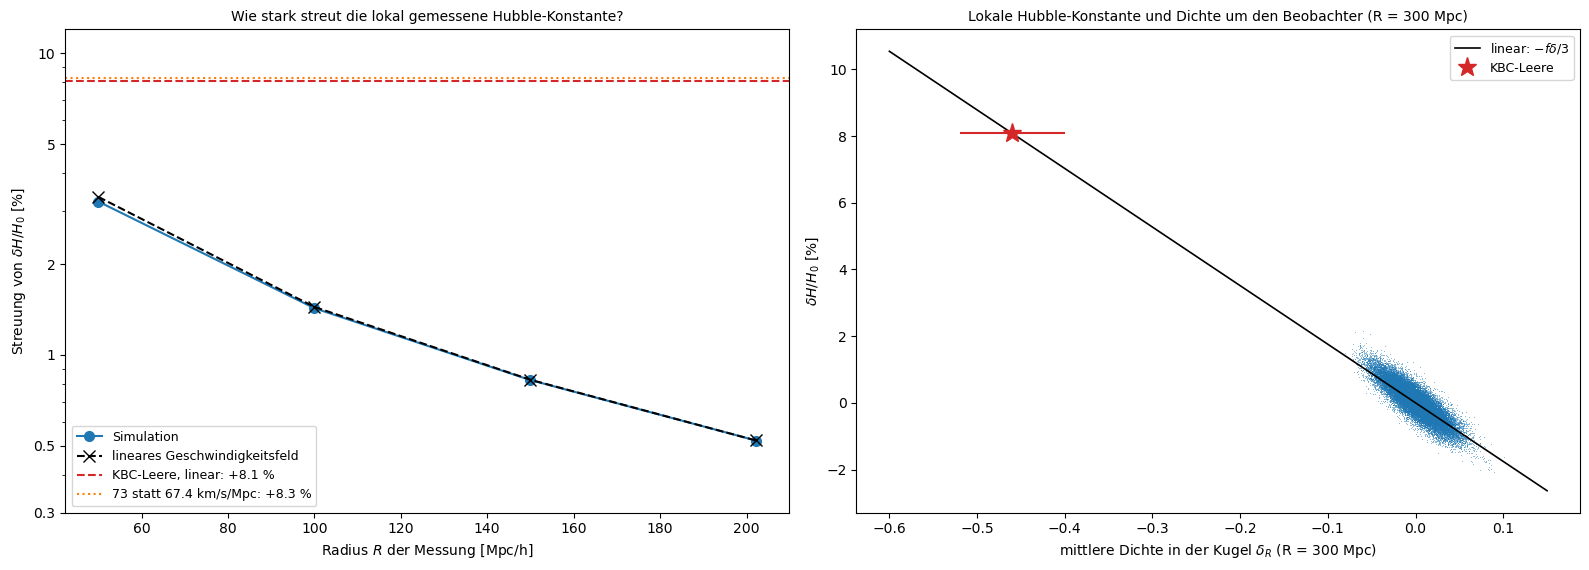

R =    50 Mpc/h ( 74 Mpc): σ(δH/H₀) = 3.225 % (linear 3.342 %), größter Wert +12.77 %
R =   100 Mpc/h (148 Mpc): σ(δH/H₀) = 1.429 % (linear 1.443 %), größter Wert +5.80 %
R =   150 Mpc/h (223 Mpc): σ(δH/H₀) = 0.826 % (linear 0.827 %), größter Wert +3.57 %
R =   202 Mpc/h (300 Mpc): σ(δH/H₀) = 0.521 % (linear 0.521 %), größter Wert +2.13 %
Steigung δH/H₀ gegen δ_R bei 300 Mpc: -0.195 (−f/3 = -0.176); KBC verlangt +8.1 % = 16σ


In [13]:
n, L = BIG["N"], BIG["L"]
norm = n**3 / len(BIG["pos"])
MOM = [fft((assign(BIG["pos"], n, np.ascontiguousarray(BIG["mom"][:, j])) * norm).astype(np.float32)) for j in range(3)]
RHOK = fft(1 + BIG["delta"])
kx, ky, kz = kgrid(n)
k2 = kx**2 + ky**2 + kz**2
k2[0, 0, 0] = 1
DLK = fft(BIG["delta_lin"])
MOM_LIN = [fft(ifft(1j * kj / k2 * DLK, n) * f_growth(1.0)) for kj in (kx, ky, kz)]      # p = f ψ bei a = 1 (Gittereinheiten)
Ug = [u * n / L for u in U]                                                               # Abstände in Gitterzellen
HL = {}
for R in [50, 100, 150, R_KBC]:
    w = ((RG >= 10) & (RG <= R)).astype(np.float32)
    Kj = [fft(-u * w) for u in Ug]
    K2 = fft((Ug[0]**2 + Ug[1]**2 + Ug[2]**2) * w)
    dH = sum(ifft(MOM[j] * Kj[j], n) for j in range(3)) / ifft(RHOK * K2, n)
    dHl = sum(ifft(MOM_LIN[j] * Kj[j], n) for j in range(3)) / float(((Ug[0]**2 + Ug[1]**2 + Ug[2]**2) * w).sum())
    HL[R] = (dH, dHl)
DH202, DHL202 = HL[R_KBC]
SLOPE = np.polyfit(D202[::11], DH202.ravel()[::11], 1)[0]
F_KBC = -f_growth(1.0) * KBC["delta"] / 3
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.8))
Rs = list(HL)
ax.semilogy(Rs, [100 * HL[R][0].std() for R in Rs], "o-", color="C0", ms=7, label="Simulation")
ax.semilogy(Rs, [100 * HL[R][1].std() for R in Rs], "x--", color="k", ms=8, label="lineares Geschwindigkeitsfeld")
ax.axhline(100 * F_KBC, color="C3", ls="--", label=f"KBC-Leere, linear: +{100 * F_KBC:.1f} %")
ax.axhline(100 * (73.0 / 67.4 - 1), color="C1", ls=":", label="73 statt 67.4 km/s/Mpc: +8.3 %")
ax.set_xlabel("Radius $R$ der Messung [Mpc/h]")
ax.set_ylabel(r"Streuung von $\delta H / H_0$ [%]")
ax.set_yticks([0.3, 0.5, 1, 2, 5, 10])
ax.set_yticklabels(["0.3", "0.5", "1", "2", "5", "10"])
ax.set_ylim(0.3, 12)
ax.set_title("Wie stark streut die lokal gemessene Hubble-Konstante?", fontsize=10)
ax.legend(fontsize=9)
sub = np.random.default_rng(9).choice(D202.size, 30000, replace=False)
ax2.plot(D202[sub], 100 * DH202.ravel()[sub], ",", color="C0", alpha=0.5)
xx = np.linspace(-0.6, 0.15, 10)
ax2.plot(xx, -100 * f_growth(1.0) * xx / 3, color="k", lw=1.2, label=r"linear: $-f\delta/3$")
ax2.errorbar(KBC["delta"], 100 * F_KBC, xerr=KBC["err"], fmt="*", color="C3", ms=14, label="KBC-Leere")
ax2.set_xlabel(r"mittlere Dichte in der Kugel $\delta_R$ (R = 300 Mpc)")
ax2.set_ylabel(r"$\delta H / H_0$ [%]")
ax2.set_title("Lokale Hubble-Konstante und Dichte um den Beobachter (R = 300 Mpc)", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

for R, (dH, dHl) in HL.items():
    print(f"R = {R:5.0f} Mpc/h ({R / PLANCK['h']:3.0f} Mpc): σ(δH/H₀) = {100 * dH.std():.3f} % (linear {100 * dHl.std():.3f} %), größter Wert {100 * dH.max():+.2f} %")
print(f"Steigung δH/H₀ gegen δ_R bei 300 Mpc: {SLOPE:+.3f} (−f/3 = {-f_growth(1.0) / 3:+.3f}); KBC verlangt +{100 * F_KBC:.1f} % = {F_KBC / DH202.std():.0f}σ")

* Links die Streuung der lokalen Hubble-Konstante über dem Radius der Messung: 3.2 % bei 50 Mpc/h (74 Mpc), 1.4 % bei 100, 0.83 % bei 150 und 0.52 % bei 202 Mpc/h (300 Mpc). Simulation (Punkte) und lineares Geschwindigkeitsfeld (Kreuze) stimmen bis auf 3 % überein; auf diesen Skalen sind die Strömungen linear. Rechts $\delta H/H_0$ gegen $\delta_R$ für 300 Mpc: Die Punkte liegen um die Gerade $-f\delta/3$. Die Steigung ist −0.195 statt −0.176; vermutlich, weil der Schätzer die äußeren Teile der Schale stärker gewichtet als die Kugel, in der $\delta_R$ gemessen ist.
* Kein Beobachter im ganzen Würfel misst bei 300 Mpc mehr als +2.1 %. Die KBC-Leere verlangt +8.1 %, das sind 16σ, und ihre Dichte (Stern) liegt weit außerhalb der Punktwolke.
* Zur Vorhersage: 8.1 / 0.52 = 16σ.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-10"></a>

##### *10. Gegen die veröffentlichten Werte*

Wie passen die eigenen Zahlen zu Haslbauer et al. (2020), zu Wu & Huterer (2017) und zu cosmology_localvoid? Vorher vorhersagen: Ist die eigene Seltenheit der KBC-Leere mit Messfehler größer oder kleiner als die 6.04σ von Haslbauer et al.?

Links stehen die Spannungen der KBC-Leere mit ΛCDM in σ: eigene Simulation ohne und mit Messfehler, die lineare Theorie aus cosmology_localvoid und Haslbauer et al. mit der Simulation Millennium-XXL. Rechts steht die Streuung der lokalen Hubble-Konstante aus Schritt 9 neben dem Wert von Wu & Huterer für eine Stichprobe von Supernovae wie bei SH0ES. Dazu kommt der Unterschied zwischen 73 und 67.4 km/s/Mpc.

**Hintergrund & Fachbegriffe:**
- **Millennium-XXL:** eine Simulation mit 303 Milliarden Teilchen in einem Würfel von 3 Gpc/h (Angulo et al. 2012); Haslbauer et al. suchten darin Leeren wie die KBC-Leere um Beobachter in Galaxien.
- **Andere Definitionen:** Haslbauer et al. vergleichen die Dichte zwischen 40 und 300 Mpc um Beobachter in Halos der Größe der Milchstraße und berücksichtigen, wie Keenan et al. Galaxien zählen; die Zahlen unterscheiden sich deshalb im Detail.

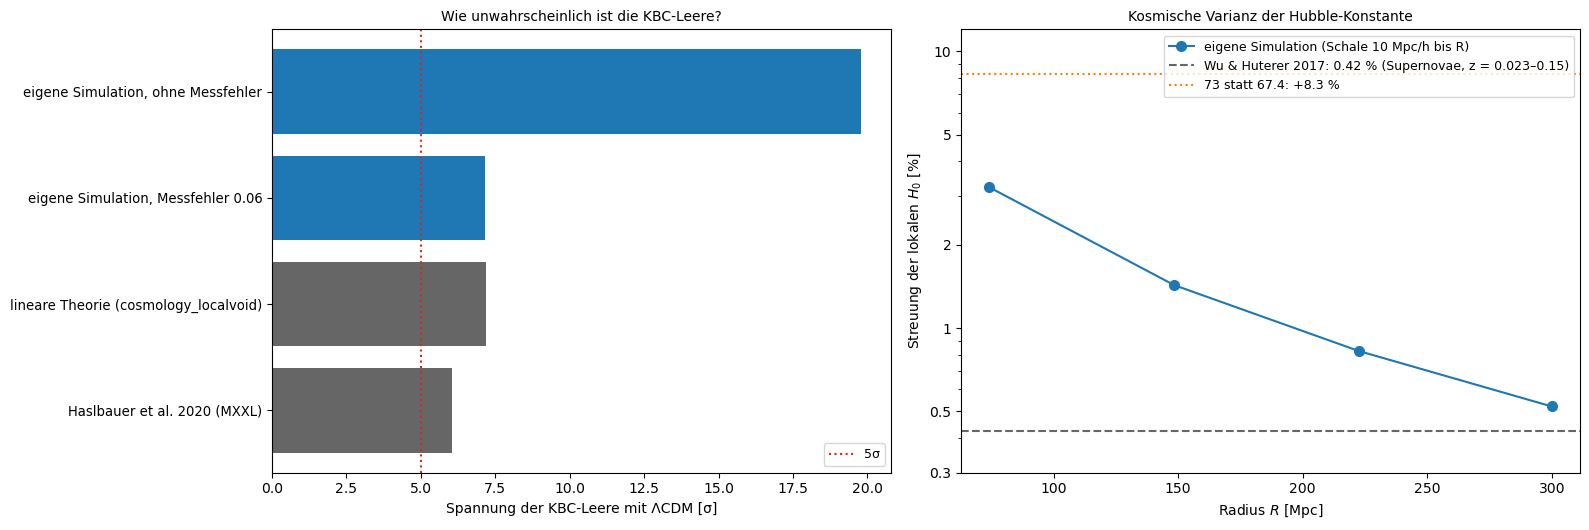

eigene Simulation, ohne Messfehler      :  19.8σ
eigene Simulation, Messfehler 0.06      :   7.1σ
lineare Theorie (cosmology_localvoid)   :   7.2σ
Haslbauer et al. 2020 (MXXL)            :   6.0σ
σ(H₀,lokal) bei 300 Mpc: 0.52 %, Wu & Huterer 0.42 %; nötig für die Spannung: 8.3 % = 16σ


In [14]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.4))
rows = [("eigene Simulation, ohne Messfehler", NU_KBC, "C0"), ("eigene Simulation, Messfehler 0.06", NU_KBC_ERR, "C0"),
        ("lineare Theorie (cosmology_localvoid)", LOCALVOID_SIGMA, "0.4"), ("Haslbauer et al. 2020 (MXXL)", HASLBAUER_SIGMA, "0.4")]
ax.barh(np.arange(len(rows)), [r[1] for r in rows], color=[r[2] for r in rows])
ax.set_yticks(np.arange(len(rows)))
ax.set_yticklabels([r[0] for r in rows], fontsize=9.5)
ax.invert_yaxis()
ax.axvline(5, color="C3", ls=":", label="5σ")
ax.set_xlabel("Spannung der KBC-Leere mit ΛCDM [σ]")
ax.set_title("Wie unwahrscheinlich ist die KBC-Leere?", fontsize=10)
ax.legend(fontsize=9)
ax2.plot([R / PLANCK["h"] for R in HL], [100 * HL[R][0].std() for R in HL], "o-", color="C0", ms=7, label="eigene Simulation (Schale 10 Mpc/h bis R)")
ax2.axhline(100 * WU_HUTERER, color="0.4", ls="--", label=f"Wu & Huterer 2017: {100 * WU_HUTERER:.2f} % (Supernovae, z = 0.023–0.15)")
ax2.axhline(100 * (73.0 / 67.4 - 1), color="C1", ls=":", label="73 statt 67.4: +8.3 %")
ax2.set_yscale("log")
ax2.set_yticks([0.3, 0.5, 1, 2, 5, 10])
ax2.set_yticklabels(["0.3", "0.5", "1", "2", "5", "10"])
ax2.set_ylim(0.3, 12)
ax2.set_xlabel("Radius $R$ [Mpc]")
ax2.set_ylabel(r"Streuung der lokalen $H_0$ [%]")
ax2.set_title("Kosmische Varianz der Hubble-Konstante", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

for lab, v, _ in rows:
    print(f"{lab:40s}: {v:5.1f}σ")
print(f"σ(H₀,lokal) bei 300 Mpc: {100 * DH202.std():.2f} %, Wu & Huterer {100 * WU_HUTERER:.2f} %; nötig für die Spannung: 8.3 % = {0.083 / DH202.std():.0f}σ")

* Links die Spannung der KBC-Leere mit ΛCDM in σ, rechts die Streuung der lokalen H₀. Mit Messfehler gibt die eigene Simulation 7.1σ, fast genau die lineare Theorie aus cosmology_localvoid (7.2σ), denn $\sigma$(300 Mpc) ist in beiden gleich (0.0232 und 0.0231). Haslbauer et al. kommen mit Millennium-XXL auf 6.0σ.
* Die eigene Streuung der lokalen H₀ bei 300 Mpc ist 0.52 %, etwas mehr als die 0.42 % von Wu & Huterer. Sie bilden die Verteilung echter Supernovae bis z = 0.15 (etwa 600 Mpc) nach, und mit der größeren Tiefe wird die Streuung kleiner. Die Hubble-Spannung braucht 8.3 %, sechzehnmal mehr.
* Zur Vorhersage: größer, 7.1 gegen 6.0σ. Der Unterschied kommt vermutlich aus der Definition: Haslbauer et al. messen die Dichte zwischen 40 und 300 Mpc um Halos wie die Milchstraße und berücksichtigen, wie Keenan et al. zählen; hier ist es eine volle Kugel um beliebige Punkte. Beide Wege sagen dasselbe: In ΛCDM gibt es eine solche Leere nicht, und die lokal gemessene H₀ streut auf 300 Mpc um weniger als 1 %.

[↑ Zurück zur Landkarte](#landkarte)

#### **Ergebnis**

Beim Lauf vom 2026-11-08 (eigener PM-Code, je $256^3$ Teilchen, Würfel von 2000 und 250 Mpc/h, Anfangsbedingungen nach Zel'dovich bei z = 49, Planck 2018):

- **Der Code wächst richtig:** Die großen Moden folgen der linearen Theorie auf 0.3 % (k < 0.1 h/Mpc). Der BAO-Peak liegt heute bei 100.1 Mpc/h statt 101.1 im Anfangsfeld, niedriger und breiter. Auf kleinen Skalen wächst die Leistung nichtlinear, bei k = 1 h/Mpc auf das Fünffache.
- **Das kosmische Netz:** Heute füllen Leeren mit $\delta < -0.5$ 68 % des Volumens mit 10 % der Masse; 40 % der Masse sitzen in 1.3 % des Volumens.
- **Dichte in Kugeln:** $\sigma(R)$ folgt der linearen Theorie ab etwa 20 Mpc/h; nichtlinear ist $\sigma_8$ = 0.90 statt 0.81. Bei 8 Mpc/h ist die Verteilung lognormal (Schiefe +3.5), bei 300 Mpc gaußisch (+0.05) mit **$\sigma$ = 0.0232**.
- **Die KBC-Leere:** $\delta$ = −0.46 in 300 Mpc liegt **19.8σ** unter dem Mittel, mit dem Messfehler von 0.06 noch **7.1σ**. Im ganzen beobachtbaren Universum erwartet man davon 5·10⁻⁸. Die leerste Kugel dieser Größe im Würfel hat $\delta$ = −0.083.
- **Leeren dieser Tiefe:** Kugeln mit $\delta \le -0.46$ sind häufig bis etwa 30 Mpc/h (1 % bei 45 Mpc), um Beobachter in Materie noch seltener, und es gibt keine einzige ab 80 Mpc/h.
- **Lokale Hubble-Konstante:** Sie streut um 0.52 % bei 300 Mpc und um 3.2 % bei 74 Mpc. Die KBC-Leere verlangte +8.1 % (16σ); kein Beobachter im Würfel misst mehr als +2.1 %.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und das Notebook neu ausführen:

1. **Ein anderes Universum:** `SEED = 2`. *(Vorhersage: Alle Moden werden neu gewürfelt, die Statistik bleibt: $\sigma$(300 Mpc) = 0.0229 statt 0.0232, die leerste Kugel −0.0835 statt −0.0827, die KBC-Leere 20.0σ und mit Messfehler 7.16σ. Ein Würfel von 2000 Mpc/h ist groß genug, dass die kosmische Varianz kaum zählt.)*
2. **Weniger Struktur:** `s8=0.76` in `PLANCK`, ungefähr der Wert aus schwachen Gravitationslinsen. *(Vorhersage: $\sigma$(300 Mpc) sinkt im selben Verhältnis auf 0.0218, die KBC-Leere wird noch seltener, 21.1σ. Mit Messfehler ändert sich fast nichts (7.21σ), weil dann der Messfehler von 0.06 die Rechnung bestimmt.)*
3. **Schritte gleichmäßig in a statt in ln a:** `A_BIG = np.linspace(0.02, 1.0, 31)`. *(Vorhersage: Der erste Schritt springt von a = 0.02 auf 0.053, viel zu grob für die frühe Zeit. Die großen Moden wachsen um 18 % zu stark in der Leistung (Schritt 3: 1.177 statt 1.003), $\sigma$(300 Mpc) wird 0.0252. Ein Fehler im Code wäre hier nur an der Prüfung gegen das Anfangsfeld zu erkennen, nicht an den Bildern.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Warum rechnet man in mitbewegten Koordinaten?</summary>

Weil die Expansion dann aus den Bewegungsgleichungen fast herausfällt: Ein Teilchen ohne Eigenbewegung bleibt bei festem $\mathbf x$. Übrig bleiben die Bewegung durch die Gravitation der Störungen und die Bremsung durch die Expansion.
</details>

<details><summary>2. Was macht der Particle-Mesh-Algorithmus in einem Schritt?</summary>

Er verteilt die Masse der Teilchen auf ein Gitter (CIC), löst die Poisson-Gleichung mit der FFT, rechnet daraus die Kraft und interpoliert sie zurück auf die Teilchen. Dann schiebt er Impulse und Orte nach Kick-Drift-Kick weiter.
</details>

<details><summary>3. Warum ist die FFT für die Poisson-Gleichung so praktisch?</summary>

Im Fourier-Raum wird aus $\nabla^2\phi$ einfach $-k^2\phi_\mathbf{k}$; die Gleichung ist dort eine Division. Mit der FFT kostet das für $N_g^3$ Zellen nur etwa $N_g^3\log N_g$ Rechenschritte.
</details>

<details><summary>4. Was ist die Zel'dovich-Näherung, und wozu dient sie hier?</summary>

Sie verschiebt die Teilchen eines regelmäßigen Gitters um ein Feld $\boldsymbol\psi$, dessen Divergenz der Dichtekontrast ist, und gibt ihnen die passende Geschwindigkeit. So entsteht bei z = 49 ein Zustand mit dem richtigen Spektrum, von dem aus die Simulation weiterrechnet.
</details>

<details><summary>5. Woran erkennt man, dass ein N-Körper-Code richtig rechnet?</summary>

An den großen Moden: Sie müssen genau wie $D^2$ wachsen. Teilt man das Spektrum am Ende Mode für Mode durch das Anfangsspektrum, fällt die Zufälligkeit heraus, und schon 1 % Abweichung fällt auf. Zu grobe Zeitschritte am Anfang gaben hier 18 % zu viel.
</details>

<details><summary>6. Warum wird σ₈ in der Simulation größer als 0.811?</summary>

0.811 ist die lineare Streuung. Kugeln von 8 Mpc/h sind heute nichtlinear: Haufen sind viel dichter, Leeren nicht leerer als leer; die Streuung wächst dadurch auf 0.90.
</details>

<details><summary>7. Warum ist die Verteilung von δ in kleinen Kugeln schief?</summary>

$\delta$ kann nicht unter −1 fallen, aber beliebig groß werden. Wenn die Streuung in die Nähe von 1 kommt, wird die Verteilung deshalb einseitig, mit einer Spitze bei negativen Werten und einem langen Ausläufer zu großen.
</details>

<details><summary>8. Warum wird der BAO-Peak breiter?</summary>

Die Teilchen bewegen sich durch die Gravitation im Mittel um etwa 10 Mpc/h. Paare, die anfangs genau 100 Mpc/h auseinander lagen, haben danach etwas verschiedene Abstände; die scharfe Schale verschmiert.
</details>

<details><summary>9. Wie selten ist eine Leere mit δ = −0.46 in 300 Mpc?</summary>

Bei $\sigma$ = 0.023 sind das 20 Standardabweichungen, mit dem Messfehler von 0.06 immer noch 7. Selbst unter den etwa $10^5$ Kugeln dieser Größe im beobachtbaren Universum erwartet man keine einzige.
</details>

<details><summary>10. Warum darf man die Gaußkurve so weit über die Simulation hinaus fortsetzen?</summary>

Auf 300 Mpc sind die Schwankungen linear und die Verteilung gaußisch; die Schiefe ist +0.05. Eine positive Schiefe macht den Ausläufer zu negativen Werten dünner, die Fortsetzung überschätzt die Wahrscheinlichkeit also eher.
</details>

<details><summary>11. Auf welchen Skalen sind Leeren mit 46 % weniger Materie gewöhnlich?</summary>

Bis etwa 30 Mpc/h Radius (45 Mpc): Dort hat jede hundertste Kugel oder mehr eine so tiefe Unterdichte. Die Lokale Leere neben der Milchstraße ist so eine.
</details>

<details><summary>12. Warum sitzt ein Beobachter in einer Galaxie meist in einer Überdichte?</summary>

Galaxien entstehen dort, wo viel Materie ist. Ein zufällig gewähltes Teilchen liegt deshalb mit größerer Wahrscheinlichkeit in einem Filament oder Haufen als ein zufälliger Punkt im Raum.
</details>

<details><summary>13. Wie hängt die lokal gemessene Hubble-Konstante mit der Dichte zusammen?</summary>

Aus einer Unterdichte strömt die Materie nach außen; die Galaxien entfernen sich schneller, als die Expansion allein es täte. Linear gilt $\delta H/H_0 \approx -f\bar\delta/3$; mit $f$ = 0.53 gibt $\bar\delta$ = −0.46 also +8 %.
</details>

<details><summary>14. Warum kann die kosmische Varianz die Hubble-Spannung nicht erklären?</summary>

Auf den Skalen, die SH0ES benutzt, streut die lokale H₀ in ΛCDM nur um etwa ein halbes Prozent. Die Spannung beträgt 8 %; dafür bräuchte es eine Leere, die es in ΛCDM nicht gibt.
</details>

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Bessere Auflösung:** ein Baum- oder Mehrgitterverfahren für die kurzen Kräfte (TreePM wie in GADGET) oder FastPM mit angepassten Schritten. Damit werden Halos aufgelöst und das nichtlineare Spektrum bei k > 1 richtig.
- **Anfangsbedingungen zweiter Ordnung (2LPT):** Sie verringern die Übergangseffekte des Zel'dovich-Starts und erlauben einen späteren Beginn.
- **Halos und Galaxien:** Halos mit Friends-of-Friends finden und mit Galaxien besetzen; dann lässt sich die KBC-Leere so messen, wie Keenan et al. Galaxien im nahen Infrarot gezählt haben, und um Beobachter in Halos wie der Milchstraße.
- **Lichtkegel und Richtungen:** Beobachter auf dem Rückwärts-Lichtkegel, mit Rotverschiebungsverzerrung und der Himmelsverteilung echter Supernovae, wie bei Wu & Huterer.
- **Andere Kosmologien:** Dieselbe Rechnung mit modifizierter Gravitation oder anderem $\sigma_8$; Haslbauer et al. schlagen vor, dass erst eine stärkere Gravitation auf großen Skalen eine KBC-Leere erlaubt.

#### **Referenzen**

- Hockney, R. W. & Eastwood, J. W. (1988): *Computer Simulation Using Particles*, Institute of Physics (Kap. 5 und 8: Particle-Mesh, Zuweisung, Fehler).
- Klypin, A. & Holtzman, J. (1997): *Particle-Mesh code for cosmological simulations*, arXiv:astro-ph/9712217.
- Zel'dovich, Ya. B. (1970): *Gravitational instability: an approximate theory for large density perturbations*, A&A 5, 84.
- Eisenstein, D. J. & Hu, W. (1998): *Baryonic features in the matter transfer function*, ApJ 496, 605.
- Dodelson, S. & Schmidt, F. (2020): *Modern Cosmology*, 2. Aufl., Academic Press (Wachstum der Strukturen, σ(R), Simulationen).
- Springel, V. (2005): *The cosmological simulation code GADGET-2*, MNRAS 364, 1105.
- Angulo, R. E. et al. (2012): *Scaling relations for galaxy clusters in the Millennium-XXL simulation*, MNRAS 426, 2046.
- Keenan, R. C., Barger, A. J. & Cowie, L. L. (2013): *Evidence for a ~300 megaparsec scale under-density in the local galaxy distribution*, ApJ 775, 62.
- Haslbauer, M., Banik, I. & Kroupa, P. (2020): *The KBC void and Hubble tension contradict ΛCDM on a Gpc scale − Milgromian dynamics as a possible solution*, MNRAS 499, 2845.
- Wu, H.-Y. & Huterer, D. (2017): *Sample variance in the local measurements of the Hubble constant*, MNRAS 471, 2003.
- Tully, R. B. & Fisher, J. R. (1987): *Nearby Galaxies Atlas*, Cambridge University Press.
- Planck Collaboration (2020): *Planck 2018 results. VI. Cosmological parameters*, A&A 641, A6.